# Zero Trust SE Detection — Leak-Free Reproduction Notebook (v3)

**Paper:** Zero Trust Enhanced Defense Mechanisms for Mitigating Social Engineering Exploitation in Online Social Networks
**Authors:** D. Saravana Kumar, Burugapalli Rohan, Raja Muthalagu, Somasundaram A., Pranav M. Pawar (BITS Pilani, Dubai Campus)

## Running this notebook

* Runs on Google Colab with a T4 GPU. All artefacts are read from and written to `MyDrive/thesis_models/v3_leakfree/` (Section 3); change `BASE_DIR` to use another location.
* **SEConvo** is downloaded automatically from Zenodo (record 12170260).
* **SE-VSim** must be obtained from its authors and placed at `MyDrive/thesis_models/sevsim/train_data.json` and `test_data.json`.
* **LoveFraud02** (Mendeley Data, doi:10.17632/kmhvb4x5d8.1) is converted to SEConvo format with `convert_lovefraud.py` and read in Section 27.
* Every train cell loads the saved checkpoint if it exists, so a re-run with the released checkpoints and cached logits reproduces the reported numbers without retraining.
* Every experiment in the paper is in this notebook, including the LoveFraud02 evaluation (Section 27), turn-level LIME (Section 28) and length-aware thresholds (Sections 28b and 28c). The reported numbers are collected in `results_v3_final.json`, and `gen_numbers.py` turns them into the LaTeX macros used by the paper.

## Evaluation protocol (what makes this version leak-free)

| Data | Used for |
|---|---|
| **Train split** (75% of the 490 SEConvo-train + SE-VSim-train pool, stratified by source × label) | Fine-tuning SecureBERT and ModernBERT |
| **Validation split** (remaining 25%) | Early stopping, temperature scaling, fusion-MLP training, Youden's J `T_block`, 75th-percentile `T_permit` |
| **SEConvo test (360)** | Scored **once**, in Section 12, after everything is frozen. Nothing is fitted or selected on it. |
| **SE-VSim test (900)** | External evaluation with the same frozen pipeline |

**Run order:** top to bottom. Sections 1–11 fit; 12 onward only evaluate. Section 20 (Mistral) frees the BERT models, so run it last.

## 1. Install & GPU check

In [ ]:
!pip install -q transformers datasets scikit-learn shap lime statsmodels accelerate
import torch
print('GPU available:', torch.cuda.is_available())
assert torch.cuda.is_available(), 'Switch the runtime to a GPU (T4) before continuing.'
print('Device:', torch.cuda.get_device_name(0))

GPU available: True
Device: Tesla T4


## 2. Imports & seeds

In [ ]:
import random, json, copy, os, gc, time, re, math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_curve, roc_auc_score, brier_score_loss)
from sklearn.model_selection import StratifiedKFold, train_test_split
from collections import Counter
import matplotlib.pyplot as plt

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

set_seed()
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device('cuda')
print(f'Seed {SEED} | device {device}')

Seed 42 | device cuda


## 3. Drive & output folder

In [ ]:
from google.colab import drive
drive.mount('/drive')

BASE_DIR = '/drive/MyDrive/thesis_models/'
RUN_DIR = os.path.join(BASE_DIR, 'v3_leakfree/')   # new folder: old checkpoints stay untouched
os.makedirs(RUN_DIR, exist_ok=True)

def rpath(name):
    return os.path.join(RUN_DIR, name)

def save_json(obj, name):
    with open(rpath(name), 'w') as f:
        json.dump(obj, f, indent=2, default=float)
    print('Saved:', rpath(name))

RESULTS = {}   # everything reportable accumulates here and is written in Section 19
print('Run dir:', RUN_DIR)

Drive already mounted at /drive; to attempt to forcibly remount, call drive.mount("/drive", force_remount=True).
Run dir: /drive/MyDrive/thesis_models/v3_leakfree/


## 4. Data, train/validation split, leakage guard

The 490-conversation training pool is split 75/25, stratified on *source × label* so both splits contain SEConvo and SE-VSim, SE and benign. The split indices are saved to `split.json` for reproducibility.

In [ ]:
import urllib.request

SEVSIM_TRAIN_PATH = os.path.join(BASE_DIR, 'sevsim/train_data.json')
SEVSIM_TEST_PATH  = os.path.join(BASE_DIR, 'sevsim/test_data.json')
VAL_FRACTION = 0.25

def load_convs(path):
    with open(path) as f:
        return json.load(f)['Conversations']

def label(c):
    return 1 if c['GroundTruth']['IsMalicious'] else 0

for name in ['annotated_train.json', 'annotated_test.json']:
    dst = f'/content/{name}'
    if not os.path.exists(dst):
        urllib.request.urlretrieve(f'https://zenodo.org/records/12170260/files/{name}', dst)

seconvo_train   = load_convs('/content/annotated_train.json')
test_raw        = load_convs('/content/annotated_test.json')
sevsim_train    = load_convs(SEVSIM_TRAIN_PATH)
sevsim_test_raw = load_convs(SEVSIM_TEST_PATH)

for c in seconvo_train: c['_source'] = 'SEConvo'
for c in sevsim_train:  c['_source'] = 'SE-VSim'
for c in test_raw:      c['_source'] = 'SEConvo'
for c in sevsim_test_raw: c['_source'] = 'SE-VSim'

pool = seconvo_train + sevsim_train
strata = [f"{c['_source']}|{label(c)}" for c in pool]
tr_idx, val_idx = train_test_split(np.arange(len(pool)), test_size=VAL_FRACTION,
                                   stratify=strata, random_state=SEED)
tr_idx, val_idx = sorted(map(int, tr_idx)), sorted(map(int, val_idx))
train_raw = [pool[i] for i in tr_idx]
val_raw   = [pool[i] for i in val_idx]
save_json({'val_fraction': VAL_FRACTION, 'seed': SEED,
           'pool_order': 'SEConvo annotated_train.json, then SE-VSim train_data.json',
           'train_pool_indices': tr_idx, 'val_pool_indices': val_idx}, 'split.json')

y_train  = np.array([label(c) for c in train_raw])
y_val    = np.array([label(c) for c in val_raw])
y_test   = np.array([label(c) for c in test_raw])
y_sevsim = np.array([label(c) for c in sevsim_test_raw])

def describe(name, convs):
    y = np.array([label(c) for c in convs])
    print(f'{name:<18} n={len(convs):>4}  SE={int(y.sum()):>4}  benign={int(len(y) - y.sum()):>4}  '
          f'sources={dict(Counter(c["_source"] for c in convs))}')

describe('Train (fit)', train_raw)
describe('Validation', val_raw)
describe('SEConvo test', test_raw)
describe('SE-VSim test', sevsim_test_raw)

# ---- Leakage guard: no conversation used for fitting may appear in an evaluation set
def conv_key(c):
    return ' || '.join(m['Message'].strip() for m in c['Conversation'])

fit_keys = set(map(conv_key, train_raw + val_raw))
overlap_test = len(fit_keys & set(map(conv_key, test_raw)))
overlap_sevsim = len(fit_keys & set(map(conv_key, sevsim_test_raw)))
print(f'\nDuplicates between fitting data and SEConvo test: {overlap_test}')
print(f'Duplicates between fitting data and SE-VSim test: {overlap_sevsim}')
assert overlap_test == 0, 'SEConvo test conversations found in fitting data!'
if overlap_sevsim:
    print('WARNING: SE-VSim test contains conversations also present in training data. Report this in the paper.')
RESULTS['data'] = {'n_train': len(train_raw), 'n_val': len(val_raw), 'n_test': len(test_raw),
                   'n_sevsim_test': len(sevsim_test_raw), 'sevsim_test_overlap_with_fit': overlap_sevsim}

Saved: /drive/MyDrive/thesis_models/v3_leakfree/split.json
Train (fit)        n= 367  SE= 243  benign= 124  sources={'SEConvo': 30, 'SE-VSim': 337}
Validation         n= 123  SE=  81  benign=  42  sources={'SEConvo': 10, 'SE-VSim': 113}
SEConvo test       n= 360  SE= 191  benign= 169  sources={'SEConvo': 360}
SE-VSim test       n= 900  SE= 600  benign= 300  sources={'SE-VSim': 900}

Duplicates between fitting data and SEConvo test: 0
Duplicates between fitting data and SE-VSim test: 0


## 5. Text representations & data loaders

* **SecureBERT** gets the SEP-joined text using the tokenizer's **real** separator token, truncated from the **left** at 512 tokens (keeps the most recent turns, as the paper states).
* **ModernBERT** gets the turn-tagged text, untruncated up to 8,192 tokens.
* Both use dynamic per-batch padding.

In [ ]:
CLASS_WEIGHTS = [1.0, 1.5]           # [benign, SE] -> misclassifying SE costs 1.5x
SECURE_CKPT = 'ehsanaghaei/SecureBERT'
MODERN_CKPT = 'answerdotai/ModernBERT-base'
MAX_LEN_SB, MAX_LEN_MB = 512, 8192

secure_tokenizer = AutoTokenizer.from_pretrained(SECURE_CKPT)
secure_tokenizer.truncation_side = 'left'
modern_tokenizer = AutoTokenizer.from_pretrained(MODERN_CKPT)
print('SecureBERT separator token:', repr(secure_tokenizer.sep_token))

def sep_text(conv):
    sep = f' {secure_tokenizer.sep_token} '
    return sep.join(f"{m['Name']}: {m['Message']}" for m in conv['Conversation'])

def turn_text(conv):
    return ' '.join(f"[TURN{i+1}] {m['Name']}: {m['Message']}" for i, m in enumerate(conv['Conversation']))

class ConvDataset(Dataset):
    def __init__(self, convs, tokenizer, text_fn, max_length):
        self.texts = [text_fn(c) for c in convs]
        self.labels = [label(c) for c in convs]
        self.tok, self.max_length = tokenizer, max_length
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        enc = self.tok(self.texts[i], truncation=True, max_length=self.max_length, return_tensors='pt')
        return {'input_ids': enc['input_ids'].squeeze(0),
                'attention_mask': enc['attention_mask'].squeeze(0),
                'label': torch.tensor(self.labels[i], dtype=torch.long)}

def make_loader(convs, tokenizer, text_fn, max_length, batch_size, shuffle=False):
    ds = ConvDataset(convs, tokenizer, text_fn, max_length)
    pad_id = tokenizer.pad_token_id
    def collate(batch):
        L = max(b['input_ids'].size(0) for b in batch)
        ids = torch.full((len(batch), L), pad_id, dtype=torch.long)
        att = torch.zeros((len(batch), L), dtype=torch.long)
        for i, b in enumerate(batch):
            n = b['input_ids'].size(0)
            ids[i, :n] = b['input_ids']; att[i, :n] = b['attention_mask']
        return {'input_ids': ids, 'attention_mask': att, 'label': torch.stack([b['label'] for b in batch])}
    g = torch.Generator(); g.manual_seed(SEED)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle,
                      generator=g if shuffle else None, collate_fn=collate)

# Token-length diagnostic (reported in the paper's pre-processing section)
def token_lengths(convs, tok, fn):
    return np.array([len(tok(fn(c), truncation=False)['input_ids']) for c in convs])

length_stats = {}
for name, convs in [('train', train_raw), ('val', val_raw), ('test', test_raw)]:
    l_sb = token_lengths(convs, secure_tokenizer, sep_text)
    l_mb = token_lengths(convs, modern_tokenizer, turn_text)
    length_stats[name] = {'sb_pct_truncated_512': float((l_sb > MAX_LEN_SB).mean() * 100),
                          'mb_mean': float(l_mb.mean()), 'mb_min': int(l_mb.min()),
                          'mb_max': int(l_mb.max()), 'mb_over_8192': int((l_mb > MAX_LEN_MB).sum())}
    print(f"{name:<6} SecureBERT truncated at 512: {length_stats[name]['sb_pct_truncated_512']:.1f}% | "
          f"ModernBERT tokens mean {l_mb.mean():.0f}, range {l_mb.min()}-{l_mb.max()}, >8192: {(l_mb > MAX_LEN_MB).sum()}")
RESULTS['token_lengths'] = length_stats

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (916 > 512). Running this sequence through the model will result in indexing errors


SecureBERT separator token: '</s>'
train  SecureBERT truncated at 512: 98.6% | ModernBERT tokens mean 1478, range 361-4444, >8192: 0
val    SecureBERT truncated at 512: 97.6% | ModernBERT tokens mean 1447, range 484-2727, >8192: 0
test   SecureBERT truncated at 512: 78.1% | ModernBERT tokens mean 751, range 107-1834, >8192: 0


## 6. Model class & training loop

Implements exactly the hyperparameters in the paper's Table: AdamW (lr 2e-5, wd 0.01), linear warm-up over 10% of optimiser steps, gradient accumulation 4, fp16, gradient clipping 1.0, class-weighted CE, early stopping (patience 5) on **validation** F1 (ties broken by lower validation loss). A checkpoint is written after every improving epoch and verified on Drive.

In [ ]:
class BERTClassifier(nn.Module):
    def __init__(self, model_name):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_name)
        self.dropout = nn.Dropout(0.3)
        self.classifier = nn.Linear(self.encoder.config.hidden_size, 2)
    def forward(self, input_ids, attention_mask):
        cls = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state[:, 0, :]
        return self.classifier(self.dropout(cls)), cls

@torch.no_grad()
def predict(model, loader):
    model.eval()
    L, E = [], []
    for b in loader:
        with torch.autocast('cuda', dtype=torch.float16):
            logits, cls = model(b['input_ids'].to(device), b['attention_mask'].to(device))
        L.append(logits.float().cpu()); E.append(cls.float().cpu())
    return torch.cat(L).numpy(), torch.cat(E)

def train_model(model, train_loader, val_loader, y_val_local, epochs, lr, accum, save_path, name, patience=5):
    optimizer = AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    total_steps = math.ceil(len(train_loader) / accum) * epochs
    warmup = int(0.1 * total_steps)
    scheduler = get_linear_schedule_with_warmup(optimizer, warmup, total_steps)
    scaler = torch.amp.GradScaler('cuda')
    w = torch.tensor(CLASS_WEIGHTS, device=device)
    best, no_improve, history = None, 0, []
    print(f'Training {name}: <= {epochs} epochs, lr={lr}, accumulation={accum}, warm-up {warmup}/{total_steps} steps')

    for epoch in range(epochs):
        model.train(); optimizer.zero_grad(set_to_none=True); running = 0.0
        for step, batch in enumerate(train_loader):
            with torch.autocast('cuda', dtype=torch.float16):
                logits, _ = model(batch['input_ids'].to(device), batch['attention_mask'].to(device))
            loss = F.cross_entropy(logits.float(), batch['label'].to(device), weight=w)
            if not torch.isfinite(loss):
                raise RuntimeError(f'Non-finite loss at epoch {epoch+1}, step {step}')
            scaler.scale(loss / accum).backward()
            running += loss.item()
            if (step + 1) % accum == 0 or (step + 1) == len(train_loader):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer); scaler.update()
                optimizer.zero_grad(set_to_none=True); scheduler.step()

        val_logits, _ = predict(model, val_loader)
        val_loss = F.cross_entropy(torch.tensor(val_logits), torch.tensor(y_val_local),
                                   weight=torch.tensor(CLASS_WEIGHTS)).item()
        val_f1 = f1_score(y_val_local, val_logits.argmax(1), zero_division=0)
        key = (round(val_f1, 4), -val_loss)
        tag = ''
        if best is None or key > best:
            best, no_improve = key, 0
            torch.save(model.state_dict(), save_path)
            if not (os.path.exists(save_path) and os.path.getsize(save_path) > 1_000_000):
                raise RuntimeError(f'Checkpoint did not land on Drive: {save_path}')
            tag = ' <- best, saved'
        else:
            no_improve += 1
        history.append({'epoch': epoch + 1, 'train_loss': running / len(train_loader),
                        'val_loss': val_loss, 'val_f1': val_f1})
        print(f'  epoch {epoch+1:>2} | train loss {running/len(train_loader):.4f} | '
              f'val loss {val_loss:.4f} | val F1 {val_f1:.4f}{tag}')
        if no_improve >= patience:
            print(f'  early stop at epoch {epoch+1}'); break

    model.load_state_dict(torch.load(save_path, map_location=device))
    save_json(history, os.path.basename(save_path).replace('.pt', '_history.json'))
    return model

print('Model class and training loop defined.')

Model class and training loop defined.


## 7. SecureBERT (Stage 1, message-level) — train or load

In [ ]:
SECURE_SAVE = rpath('securebert_v3.pt')
sb_train_loader = make_loader(train_raw, secure_tokenizer, sep_text, MAX_LEN_SB, batch_size=4, shuffle=True)
sb_val_loader   = make_loader(val_raw,   secure_tokenizer, sep_text, MAX_LEN_SB, batch_size=8)

set_seed()
securebert_model = BERTClassifier(SECURE_CKPT).to(device)
if os.path.exists(SECURE_SAVE):
    securebert_model.load_state_dict(torch.load(SECURE_SAVE, map_location=device))
    print('SecureBERT v3 checkpoint loaded from Drive.')
else:
    securebert_model = train_model(securebert_model, sb_train_loader, sb_val_loader, y_val,
                                   epochs=20, lr=2e-5, accum=4, save_path=SECURE_SAVE, name='SecureBERT')
securebert_model.eval()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: ehsanaghaei/SecureBERT
Key                       | Status     | 
--------------------------+------------+-
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


SecureBERT v3 checkpoint loaded from Drive.


BERTClassifier(
  (encoder): RobertaModel(
    (embeddings): RobertaEmbeddings(
      (word_embeddings): Embedding(50265, 768, padding_idx=1)
      (token_type_embeddings): Embedding(1, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (position_embeddings): Embedding(514, 768, padding_idx=1)
    )
    (encoder): RobertaEncoder(
      (layer): ModuleList(
        (0-11): 12 x RobertaLayer(
          (attention): RobertaAttention(
            (self): RobertaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): RobertaSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): Laye

## 8. ModernBERT (Stage 2, sequence-level, untruncated) — train or load

In [ ]:
MODERN_SAVE = rpath('modernbert_v3_untruncated.pt')
mb_train_loader = make_loader(train_raw, modern_tokenizer, turn_text, MAX_LEN_MB, batch_size=1, shuffle=True)
mb_val_loader   = make_loader(val_raw,   modern_tokenizer, turn_text, MAX_LEN_MB, batch_size=2)

set_seed()
modernbert_model = BERTClassifier(MODERN_CKPT).to(device)
if os.path.exists(MODERN_SAVE):
    modernbert_model.load_state_dict(torch.load(MODERN_SAVE, map_location=device))
    print('ModernBERT v3 checkpoint loaded from Drive.')
else:
    modernbert_model = train_model(modernbert_model, mb_train_loader, mb_val_loader, y_val,
                                   epochs=10, lr=2e-5, accum=4, save_path=MODERN_SAVE, name='ModernBERT (untruncated)')
modernbert_model.eval()

Loading weights:   0%|          | 0/134 [00:00<?, ?it/s]

[transformers] ModernBertModel LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     |  | 
------------------+------------+--+-
head.norm.weight  | UNEXPECTED |  | 
decoder.bias      | UNEXPECTED |  | 
head.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


ModernBERT v3 checkpoint loaded from Drive.


BERTClassifier(
  (encoder): ModernBertModel(
    (embeddings): ModernBertEmbeddings(
      (tok_embeddings): Embedding(50368, 768, padding_idx=50283)
      (norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (drop): Dropout(p=0.0, inplace=False)
    )
    (layers): ModuleList(
      (0): ModernBertEncoderLayer(
        (attn_norm): Identity()
        (attn): ModernBertAttention(
          (Wqkv): Linear(in_features=768, out_features=2304, bias=False)
          (Wo): Linear(in_features=768, out_features=768, bias=False)
          (out_drop): Identity()
        )
        (mlp_norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (mlp): ModernBertMLP(
          (Wi): Linear(in_features=768, out_features=2304, bias=False)
          (act): GELUActivation()
          (drop): Dropout(p=0.0, inplace=False)
          (Wo): Linear(in_features=1152, out_features=768, bias=False)
        )
      )
      (1-21): 21 x ModernBertEncoderLayer(
        (attn_norm): Layer

## 9. Encoder outputs on the validation split

In [ ]:
def encoder_outputs(convs):
    sb_logits, sb_emb = predict(securebert_model, make_loader(convs, secure_tokenizer, sep_text, MAX_LEN_SB, 8))
    mb_logits, mb_emb = predict(modernbert_model, make_loader(convs, modern_tokenizer, turn_text, MAX_LEN_MB, 2))
    return {'sb_logits': sb_logits, 'mb_logits': mb_logits, 'sb_emb': sb_emb, 'mb_emb': mb_emb}

val_out = encoder_outputs(val_raw)
print('Validation outputs:', {k: tuple(v.shape) for k, v in val_out.items()})
# NOTE: test outputs are deliberately NOT computed until Section 12.

Validation outputs: {'sb_logits': (123, 2), 'mb_logits': (123, 2), 'sb_emb': (123, 768), 'mb_emb': (123, 768)}


## 10. Temperature scaling (fitted on validation)

Fitted directly on the logit margin `z = l_SE − l_benign` (no probability→logit round trip), with `T = exp(log T)` to keep it positive.

In [ ]:
def margin(logits):
    return logits[:, 1] - logits[:, 0]

def fit_temperature(logits, y):
    z = torch.tensor(margin(logits), dtype=torch.float64)
    t = torch.tensor(y, dtype=torch.float64)
    log_t = torch.zeros(1, dtype=torch.float64, requires_grad=True)
    opt = torch.optim.LBFGS([log_t], lr=0.1, max_iter=500, line_search_fn='strong_wolfe')
    def closure():
        opt.zero_grad()
        loss = F.binary_cross_entropy_with_logits(z / log_t.exp(), t)
        loss.backward()
        return loss
    opt.step(closure)
    return float(log_t.detach().exp())

def calibrate(logits, T):
    return 1.0 / (1.0 + np.exp(-margin(logits) / T))

def ece(p, y, n_bins=10):
    edges = np.linspace(0, 1, n_bins + 1); e = 0.0
    for i in range(n_bins):
        hi = (p <= edges[i + 1]) if i == n_bins - 1 else (p < edges[i + 1])
        m = (p >= edges[i]) & hi
        if m.any():
            e += m.mean() * abs(y[m].mean() - p[m].mean())
    return float(e)

T_SB = fit_temperature(val_out['sb_logits'], y_val)
T_MB = fit_temperature(val_out['mb_logits'], y_val)

calib_report = {}
for name, logits, T in [('securebert', val_out['sb_logits'], T_SB), ('modernbert', val_out['mb_logits'], T_MB)]:
    raw, cal = calibrate(logits, 1.0), calibrate(logits, T)
    calib_report[name] = {'temperature': round(T, 4),
                          'val_brier_raw': round(brier_score_loss(y_val, raw), 4), 'val_brier_cal': round(brier_score_loss(y_val, cal), 4),
                          'val_ece_raw': round(ece(raw, y_val), 4), 'val_ece_cal': round(ece(cal, y_val), 4)}
    print(f"{name:<11} T={T:.4f} | val Brier {calib_report[name]['val_brier_raw']:.4f} -> {calib_report[name]['val_brier_cal']:.4f}"
          f" | val ECE {calib_report[name]['val_ece_raw']:.4f} -> {calib_report[name]['val_ece_cal']:.4f}")

securebert  T=1.3527 | val Brier 0.1590 -> 0.1543 | val ECE 0.0996 -> 0.0839
modernbert  T=3.0570 | val Brier 0.0616 -> 0.0582 | val ECE 0.0603 -> 0.0370


## 11. Conflict-Aware fusion MLP (trained on validation)

Features: `z = [p_SB, p_MB, |p_SB − p_MB|]`. The first cell prints a diagnostic comparing the old embedding-cosine conflict with the new probability-based one — use it in the paper to justify the change.

The MLP (3 → 16 → 1, 81 parameters) is trained full-batch with Adam and L2 weight decay. `MLP_EPOCHS` is raised from 300 to 1000: with 300 full-batch steps the network under-fits and its outputs are squashed into a narrow band. That squashing is why the old trust scores topped out near 66. **Update the paper's hyperparameter table to whatever value you run.**

In [ ]:
def fusion_features(p_sb, p_mb):
    return np.column_stack([p_sb, p_mb, np.abs(p_sb - p_mb)]).astype(np.float32)

p_sb_val = calibrate(val_out['sb_logits'], T_SB)
p_mb_val = calibrate(val_out['mb_logits'], T_MB)
X_val = fusion_features(p_sb_val, p_mb_val)

# ---- Diagnostic: is either "conflict" signal informative on its own?
legacy_cos = 1 - (F.normalize(val_out['sb_emb'], dim=1) * F.normalize(val_out['mb_emb'], dim=1)).sum(1).numpy()
conflict_diag = {}
for name, s in [('legacy CLS-cosine conflict', legacy_cos), ('|p_SB - p_MB| conflict', X_val[:, 2])]:
    conflict_diag[name] = {'mean_se': float(s[y_val == 1].mean()), 'mean_benign': float(s[y_val == 0].mean()),
                           'auroc_alone': float(roc_auc_score(y_val, s))}
    print(f"{name:<28} mean SE={s[y_val == 1].mean():.4f}  benign={s[y_val == 0].mean():.4f}  "
          f"AUROC alone={roc_auc_score(y_val, s):.3f}  (0.5 = uninformative)")
RESULTS['conflict_diagnostic_val'] = conflict_diag

legacy CLS-cosine conflict   mean SE=0.9846  benign=0.9597  AUROC alone=0.879  (0.5 = uninformative)
|p_SB - p_MB| conflict       mean SE=0.1675  benign=0.3488  AUROC alone=0.253  (0.5 = uninformative)


In [ ]:
class FusionMLP(nn.Module):
    def __init__(self, n_in):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_in, 16), nn.ReLU(), nn.Linear(16, 1), nn.Sigmoid())
    def forward(self, x):
        return self.net(x).squeeze(1)

MLP_EPOCHS, MLP_LR, MLP_WD = 1000, 1e-3, 0.01

def train_mlp(X, y, n_in, seed=SEED):
    torch.manual_seed(seed)
    m = FusionMLP(n_in).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=MLP_LR, weight_decay=MLP_WD)
    Xt = torch.tensor(X, dtype=torch.float32, device=device)
    yt = torch.tensor(y, dtype=torch.float32, device=device)
    for _ in range(MLP_EPOCHS):
        m.train(); opt.zero_grad()
        loss = F.binary_cross_entropy(m(Xt), yt)
        loss.backward(); opt.step()
    m.eval()
    return m

def mlp_predict(m, X):
    with torch.no_grad():
        return m(torch.tensor(X, dtype=torch.float32, device=device)).cpu().numpy()

def cv_estimate(X, y, n_in, k=5):
    skf = StratifiedKFold(k, shuffle=True, random_state=SEED)
    f1s, aucs = [], []
    for tr, va in skf.split(X, y):
        m = train_mlp(X[tr], y[tr], n_in)
        r = mlp_predict(m, X[va])
        f1s.append(f1_score(y[va], (r >= 0.5).astype(int), zero_division=0))
        aucs.append(roc_auc_score(y[va], r))
    return np.array(f1s), np.array(aucs)

print('Parameter count, full MLP:', sum(p.numel() for p in FusionMLP(3).parameters()))
print('Parameter count, no-conflict MLP:', sum(p.numel() for p in FusionMLP(2).parameters()))

cv_full_f1, cv_full_auc = cv_estimate(X_val, y_val, 3)
cv_nc_f1, cv_nc_auc     = cv_estimate(X_val[:, :2], y_val, 2)
print(f'5-fold CV on validation, full MLP:        F1 {cv_full_f1.mean():.4f} +/- {cv_full_f1.std():.4f} | AUROC {cv_full_auc.mean():.4f} +/- {cv_full_auc.std():.4f}')
print(f'5-fold CV on validation, no-conflict MLP: F1 {cv_nc_f1.mean():.4f} +/- {cv_nc_f1.std():.4f} | AUROC {cv_nc_auc.mean():.4f} +/- {cv_nc_auc.std():.4f}')
RESULTS['mlp_cv_on_validation'] = {
    'full': {'f1_mean': float(cv_full_f1.mean()), 'f1_std': float(cv_full_f1.std()), 'fold_f1': cv_full_f1.tolist(),
             'auroc_mean': float(cv_full_auc.mean())},
    'no_conflict': {'f1_mean': float(cv_nc_f1.mean()), 'f1_std': float(cv_nc_f1.std()), 'auroc_mean': float(cv_nc_auc.mean())},
    'epochs': MLP_EPOCHS, 'lr': MLP_LR, 'weight_decay': MLP_WD}

# ---- Final models: trained on ALL validation data (no best-fold selection)
MLP_SAVE, MLP_NC_SAVE = rpath('fusion_mlp_full_v3.pt'), rpath('fusion_mlp_noconflict_v3.pt')
for path, n_in, X in [(MLP_SAVE, 3, X_val), (MLP_NC_SAVE, 2, X_val[:, :2])]:
    if not os.path.exists(path):
        torch.save(train_mlp(X, y_val, n_in).state_dict(), path)
        print('Trained and saved:', path)
mlp_full = FusionMLP(3).to(device); mlp_full.load_state_dict(torch.load(MLP_SAVE, map_location=device)); mlp_full.eval()
mlp_nc   = FusionMLP(2).to(device); mlp_nc.load_state_dict(torch.load(MLP_NC_SAVE, map_location=device)); mlp_nc.eval()
print('Fusion MLPs ready.')

Parameter count, full MLP: 81
Parameter count, no-conflict MLP: 65
5-fold CV on validation, full MLP:        F1 0.9514 +/- 0.0346 | AUROC 0.9466 +/- 0.0559
5-fold CV on validation, no-conflict MLP: F1 0.9514 +/- 0.0346 | AUROC 0.9634 +/- 0.0359
Fusion MLPs ready.


## 12. Zero Trust thresholds (derived on validation) & freeze

* `R_block` = Youden's J optimum of the full system on validation (`T_block = 100·(1 − R_block)`).
* `T_permit` = 75th percentile of **benign validation** trust scores.
* Every ablation variant gets its own validation-derived Youden threshold.

After this cell the pipeline is frozen and written to `frozen_config.json`.

In [ ]:
FULL = 'Proposed (MLP + conflict)'
VARIANTS = ['SecureBERT only', 'ModernBERT only', 'Simple average (no training)', 'MLP fusion, no conflict', FULL]

def all_variant_scores(out):
    p_sb = calibrate(out['sb_logits'], T_SB)
    p_mb = calibrate(out['mb_logits'], T_MB)
    X = fusion_features(p_sb, p_mb)
    return {'SecureBERT only': p_sb,
            'ModernBERT only': p_mb,
            'Simple average (no training)': (p_sb + p_mb) / 2,
            'MLP fusion, no conflict': mlp_predict(mlp_nc, X[:, :2]),
            FULL: mlp_predict(mlp_full, X)}

def youden_threshold(y, scores):
    fpr, tpr, thr = roc_curve(y, scores)
    k = int(np.argmax(tpr - fpr))
    return float(min(thr[k], 1.0)), float(tpr[k] - fpr[k])

R_val = all_variant_scores(val_out)
THRESH = {k: youden_threshold(y_val, R_val[k])[0] for k in VARIANTS}

R_BLOCK, J_VAL = youden_threshold(y_val, R_val[FULL])
T_BLOCK = 100 * (1 - R_BLOCK)
T_val_full = 100 * (1 - R_val[FULL])
PERMIT_PCT = 75
T_PERMIT = float(np.percentile(T_val_full[y_val == 0], PERMIT_PCT))
R_PERMIT = 1 - T_PERMIT / 100
assert T_PERMIT > T_BLOCK, f'Threshold inversion: T_permit={T_PERMIT:.2f} <= T_block={T_BLOCK:.2f}'

def zt_zone(R):
    R = np.asarray(R)
    return np.where(R >= R_BLOCK, 'Blocked', np.where(R <= R_PERMIT, 'Full Access', 'Restricted'))

print(f"Youden's J (validation): {J_VAL:.4f}")
print(f'R_block = {R_BLOCK:.4f}  ->  T_block = {T_BLOCK:.2f}   (Blocked  <=>  R >= R_block)')
print(f'T_permit = {T_PERMIT:.2f} ({PERMIT_PCT}th pct of benign validation trust scores)')
print(f'Validation trust-score range: {T_val_full.min():.1f} - {T_val_full.max():.1f}  '
      f'(a narrow range means the MLP output is saturated; raise MLP_EPOCHS)')
for k in VARIANTS:
    print(f'  {k:<30} val-derived threshold R >= {THRESH[k]:.4f}')

frozen = {'protocol': 'All fitting/tuning on validation split; SEConvo test scored once afterwards.',
          'T_securebert': T_SB, 'T_modernbert': T_MB,
          'R_block': R_BLOCK, 'T_block': T_BLOCK, 'youden_J_val': J_VAL,
          'T_permit': T_PERMIT, 'R_permit': R_PERMIT, 'permit_percentile': PERMIT_PCT,
          'variant_thresholds': THRESH, 'checkpoints': [SECURE_SAVE, MODERN_SAVE, MLP_SAVE, MLP_NC_SAVE]}
save_json(frozen, 'frozen_config.json')
RESULTS['frozen_config'] = frozen
RESULTS['calibration'] = calib_report

Youden's J (validation): 0.8792
R_block = 0.7838  ->  T_block = 21.62   (Blocked  <=>  R >= R_block)
T_permit = 82.89 (75th pct of benign validation trust scores)
Validation trust-score range: 6.9 - 84.8  (a narrow range means the MLP output is saturated; raise MLP_EPOCHS)
  SecureBERT only                val-derived threshold R >= 0.8068
  ModernBERT only                val-derived threshold R >= 0.7236
  Simple average (no training)   val-derived threshold R >= 0.7328
  MLP fusion, no conflict        val-derived threshold R >= 0.8155
  Proposed (MLP + conflict)      val-derived threshold R >= 0.7838
Saved: /drive/MyDrive/thesis_models/v3_leakfree/frozen_config.json


## 13. SEConvo test — single evaluation pass

Everything below is **evaluation only**. If you change anything above this line after looking at these numbers, the test set is no longer clean. Any such change must be reported.

In [ ]:
test_out = encoder_outputs(test_raw)
R_test = all_variant_scores(test_out)

def metrics_at(y, R, thr):
    pred = (R >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {'threshold': float(thr), 'f1': f1_score(y, pred, zero_division=0), 'accuracy': accuracy_score(y, pred),
            'recall': recall_score(y, pred, zero_division=0), 'precision': precision_score(y, pred, zero_division=0),
            'auroc': roc_auc_score(y, R), 'fpr': fp / (fp + tn) if (fp + tn) else 0.0,
            'TP': int(tp), 'FP': int(fp), 'FN': int(fn), 'TN': int(tn)}

main = metrics_at(y_test, R_test[FULL], R_BLOCK)
zones = zt_zone(R_test[FULL])
zc = Counter(zones)
se_blocked = int(((zones == 'Blocked') & (y_test == 1)).sum())
se_full_access = int(((zones == 'Full Access') & (y_test == 1)).sum())

# Bootstrap 95% CIs (resampling the test set; no fitting involved)
rng = np.random.default_rng(SEED)
boot_f1, boot_auc = [], []
for _ in range(1000):
    idx = rng.integers(0, len(y_test), len(y_test))
    if len(np.unique(y_test[idx])) < 2:
        continue
    boot_f1.append(f1_score(y_test[idx], (R_test[FULL][idx] >= R_BLOCK).astype(int), zero_division=0))
    boot_auc.append(roc_auc_score(y_test[idx], R_test[FULL][idx]))
ci_f1, ci_auc = np.percentile(boot_f1, [2.5, 97.5]), np.percentile(boot_auc, [2.5, 97.5])

print('=' * 64)
print('PROPOSED SYSTEM — SEConvo test (360), frozen validation-derived thresholds')
print('=' * 64)
for k in ['f1', 'accuracy', 'recall', 'precision', 'auroc', 'fpr']:
    print(f'{k:<10} {main[k]:.4f}')
print(f"TP={main['TP']} FP={main['FP']} FN={main['FN']} TN={main['TN']}")
print(f'95% bootstrap CI  F1 [{ci_f1[0]:.4f}, {ci_f1[1]:.4f}] | AUROC [{ci_auc[0]:.4f}, {ci_auc[1]:.4f}]')
print(f"ConvoSentinel reported F1 = 0.74 -> {'outside' if ci_f1[0] > 0.74 or ci_f1[1] < 0.74 else 'INSIDE'} our F1 CI")
print(f"\nZones: Full Access {zc['Full Access']} ({zc['Full Access']/len(zones)*100:.1f}%) | "
      f"Restricted {zc['Restricted']} ({zc['Restricted']/len(zones)*100:.1f}%) | Blocked {zc['Blocked']} ({zc['Blocked']/len(zones)*100:.1f}%)")
print(f'SE conversations Blocked: {se_blocked}/{int(y_test.sum())} ({se_blocked/y_test.sum()*100:.1f}%)')
print(f'SE conversations reaching Full Access: {se_full_access}/{int(y_test.sum())}  <- report this; it is the security-critical leak rate')

# Calibration on held-out test (report only)
for name, key, T in [('securebert', 'sb_logits', T_SB), ('modernbert', 'mb_logits', T_MB)]:
    raw, cal = calibrate(test_out[key], 1.0), calibrate(test_out[key], T)
    calib_report[name].update({'test_brier_raw': round(brier_score_loss(y_test, raw), 4), 'test_brier_cal': round(brier_score_loss(y_test, cal), 4),
                               'test_ece_raw': round(ece(raw, y_test), 4), 'test_ece_cal': round(ece(cal, y_test), 4)})
    print(f"{name:<11} held-out test Brier {calib_report[name]['test_brier_raw']:.4f} -> {calib_report[name]['test_brier_cal']:.4f} | "
          f"ECE {calib_report[name]['test_ece_raw']:.4f} -> {calib_report[name]['test_ece_cal']:.4f}")

RESULTS['test_main'] = {**main, 'ci95_f1': ci_f1.tolist(), 'ci95_auroc': ci_auc.tolist(),
                        'zones': {k: int(v) for k, v in zc.items()}, 'se_blocked': se_blocked,
                        'se_full_access': se_full_access, 'n_se': int(y_test.sum())}

PROPOSED SYSTEM — SEConvo test (360), frozen validation-derived thresholds
f1         0.7644
accuracy   0.7500
recall     0.7644
precision  0.7644
auroc      0.8247
fpr        0.2663
TP=146 FP=45 FN=45 TN=124
95% bootstrap CI  F1 [0.7155, 0.8096] | AUROC [0.7779, 0.8645]
ConvoSentinel reported F1 = 0.74 -> INSIDE our F1 CI

Zones: Full Access 15 (4.2%) | Restricted 154 (42.8%) | Blocked 191 (53.1%)
SE conversations Blocked: 146/191 (76.4%)
SE conversations reaching Full Access: 2/191  <- report this; it is the security-critical leak rate
securebert  held-out test Brier 0.2693 -> 0.2477 | ECE 0.2080 -> 0.1424
modernbert  held-out test Brier 0.2376 -> 0.1953 | ECE 0.2389 -> 0.1505


In [ ]:
# ===== Cell A: reload canonical results so later saves never overwrite them =====
RESULTS = json.load(open(rpath('results_v3.json')))
need = ['test_main', 'crossfit_seconvo', 'robustness_crossfit']
print('Loaded results_v3.json with', len(RESULTS), 'sections; present:', [k for k in need if k in RESULTS])
assert all(k in RESULTS for k in need), 'Canonical results missing — stop and restore results_v3_backup.json'

Loaded results_v3.json with 18 sections; present: ['test_main', 'crossfit_seconvo', 'robustness_crossfit']


## Section 27 — LoveFraud02 (real romance-fraud conversations): online prefix evaluation

In [ ]:
from statsmodels.stats.proportion import proportion_confint
LF_PATH = os.path.join(BASE_DIR, 'data/lovefraud02_seconvo_format.json')
lf = json.load(open(LF_PATH))['Conversations']
PAY = ['send money', 'pay ', 'payment', 'transfer', 'bitcoin', 'gift card', 'itunes', 'western union', 'fee']
first_pay = [next((i + 1 for i, m in enumerate(c['Conversation'])
                   if m['Name'] != 'Pamela' and any(w in m['Message'].lower() for w in PAY)), None) for c in lf]

CUTS = [3, 5, 8, 10, 15, 20, 30, 40, 50, 75, 100, 150, 200, 300, 500, 750, 1000, 1500, 2000, 3000]
items = []
for i, c in enumerate(lf):
    n = len(c['Conversation'])
    items += [(i, k) for k in sorted(set([k for k in CUTS if k < n] + [n]))]
items = np.array(items)

LF_CACHE = rpath('lovefraud_prefix_logits.npz')
if os.path.exists(LF_CACHE) and len(np.load(LF_CACHE)['sb']) == len(items):
    d = np.load(LF_CACHE); sbL, mbL = d['sb'], d['mb']; print('Loaded cached LoveFraud02 logits.')
else:
    prefixes = [{'Conversation': lf[i]['Conversation'][:k], 'GroundTruth': {'IsMalicious': True}} for i, k in items]
    modern_tokenizer.truncation_side = 'left'          # long prefixes keep the most recent 8192 tokens
    o = encoder_outputs(prefixes)
    modern_tokenizer.truncation_side = 'right'
    sbL, mbL = o['sb_logits'], o['mb_logits']
    np.savez(LF_CACHE, sb=sbL, mb=mbL, items=items); print(f'Scored and cached {len(items)} prefixes.')

tsbB, tmbB = fit_temperature(test_out['sb_logits'], y_test), fit_temperature(test_out['mb_logits'], y_test)
XB = fusion_features(calibrate(test_out['sb_logits'], tsbB), calibrate(test_out['mb_logits'], tmbB))
mlpB = train_mlp(XB, y_test, 3)
sB = {'ModernBERT only': XB[:, 1], FULL: mlp_predict(mlpB, XB)}
CONFIGS = {
    'A: strict (validation-fit)': dict(tsb=T_SB, tmb=T_MB, mlp=mlp_full, r_permit=R_PERMIT,
                                       thr={'ModernBERT only': THRESH['ModernBERT only'], FULL: R_BLOCK}),
    'B: SEConvo-calibrated':      dict(tsb=tsbB, tmb=tmbB, mlp=mlpB,
                                       r_permit=1 - np.percentile(100 * (1 - sB[FULL][y_test == 0]), 75) / 100,
                                       thr={k: youden_threshold(y_test, v)[0] for k, v in sB.items()})}

def wilson(k, n):
    lo, hi = proportion_confint(k, n, method='wilson'); return f'{k}/{n} = {k/n*100:.1f}% [{lo*100:.1f}, {hi*100:.1f}]'

lf_results = {}
for cname, cfg in CONFIGS.items():
    psb, pmb = calibrate(sbL, cfg['tsb']), calibrate(mbL, cfg['tmb'])
    scores = {'ModernBERT only': pmb, FULL: mlp_predict(cfg['mlp'], fusion_features(psb, pmb))}
    print(f'\n==================== {cname} ====================')
    lf_results[cname] = {}
    for v, s in scores.items():
        first, final, before_pay, never_left_full, final_zone = [], [], [], 0, []
        for i in range(len(lf)):
            idx = np.where(items[:, 0] == i)[0]; cuts, si = items[idx, 1], s[idx]
            flag = si >= cfg['thr'][v]
            final.append(bool(flag[-1]))
            f = int(cuts[np.argmax(flag)]) if flag.any() else None
            first.append(f)
            if first_pay[i] is not None:
                before_pay.append(f is not None and f < first_pay[i])
            if v == FULL:
                final_zone.append('Blocked' if flag[-1] else ('Full Access' if si[-1] <= cfg['r_permit'] else 'Restricted'))
                never_left_full += int(np.all(si <= cfg['r_permit']))
        det = [f for f in first if f is not None]
        print(f'-- {v}')
        print(f'   Flagged on full conversation:         {wilson(sum(final), len(lf))}')
        print(f'   Flagged at any point (online):        {wilson(len(det), len(lf))}')
        if det:
            print(f'   First-flag message: median {np.median(det):.0f}, mean {np.mean(det):.1f}')
        print(f'   Flagged BEFORE first payment request: {wilson(sum(before_pay), len(before_pay))}')
        for k in [10, 20, 50, 100]:
            print(f'   Flagged by message {k:>3}: {sum(f is not None and f <= k for f in first)}/{len(lf)}')
        res = {'recall_full': sum(final) / len(lf), 'recall_online': len(det) / len(lf),
               'median_first_flag': float(np.median(det)) if det else None,
               'before_payment': sum(before_pay) / len(before_pay)}
        if v == FULL:
            zc = Counter(final_zone)
            print(f'   Final ZT zone: {dict(zc)} | never left Full Access: {never_left_full}/{len(lf)}')
            res.update({'final_zones': {k: int(n) for k, n in zc.items()}, 'never_left_full_access': never_left_full})
        lf_results[cname][v] = res
RESULTS['lovefraud02'] = lf_results
save_json(RESULTS, 'results_v3.json')

Scored and cached 1253 prefixes.

==================== A: strict (validation-fit) ====================
-- ModernBERT only
   Flagged on full conversation:         79/83 = 95.2% [88.3, 98.1]
   Flagged at any point (online):        79/83 = 95.2% [88.3, 98.1]
   First-flag message: median 50, mean 56.7
   Flagged BEFORE first payment request: 33/78 = 42.3% [32.0, 53.4]
   Flagged by message  10: 6/83
   Flagged by message  20: 11/83
   Flagged by message  50: 42/83
   Flagged by message 100: 77/83
-- Proposed (MLP + conflict)
   Flagged on full conversation:         79/83 = 95.2% [88.3, 98.1]
   Flagged at any point (online):        79/83 = 95.2% [88.3, 98.1]
   First-flag message: median 50, mean 58.3
   Flagged BEFORE first payment request: 31/78 = 39.7% [29.6, 50.8]
   Flagged by message  10: 6/83
   Flagged by message  20: 11/83
   Flagged by message  50: 42/83
   Flagged by message 100: 76/83
   Final ZT zone: {'Blocked': 79, 'Restricted': 4} | never left Full Access: 0/83

========

## Section 28 — LIME on the full system (turn-level), legible figure
Explains the **full pipeline's** risk R (both encoders + calibration + fusion), not SecureBERT alone.
Each conversation turn is one interpretable feature; removed turns are dropped from the conversation.
Saves `lime_full.png` → upload to Overleaf **as `lime.png`**. Also prints the top turns for the paper text.


SE conversation (Blocked) (T = 6.9)
  +0.080  Adam: Great to hear that you're interested, Amanda! The opportunity is truly one-time and could be life-changing. To get the ball rolling, I
  +0.074  Adam: Thank you for the details, Amanda. I will need both Professor Hughes' email and phone number to verify your academic standing from our
  +0.066  Adam: You're doing great, Amanda. I've received the academic record, and it looks solid. I'll be in touch with Professor Hughes shortly. Mea
  +0.054  Adam: Got it, Amanda—the picture is perfect. Your proactiveness is going to pay off. I'll have everything processed on my end as quickly as 
  -0.038  Adam: Hi Amanda, I'm Adam, reaching out from Innovation Seed Fund. I came across your profile and was impressed with your work in renewable 
  +0.037  Amanda: Okay, I understand. Professor Hughes' email is [email protected] and her office number is (650) 555-1234. I'm attaching my academic 
  +0.025  Adam: Fantastic, Amanda! I've got all your deta

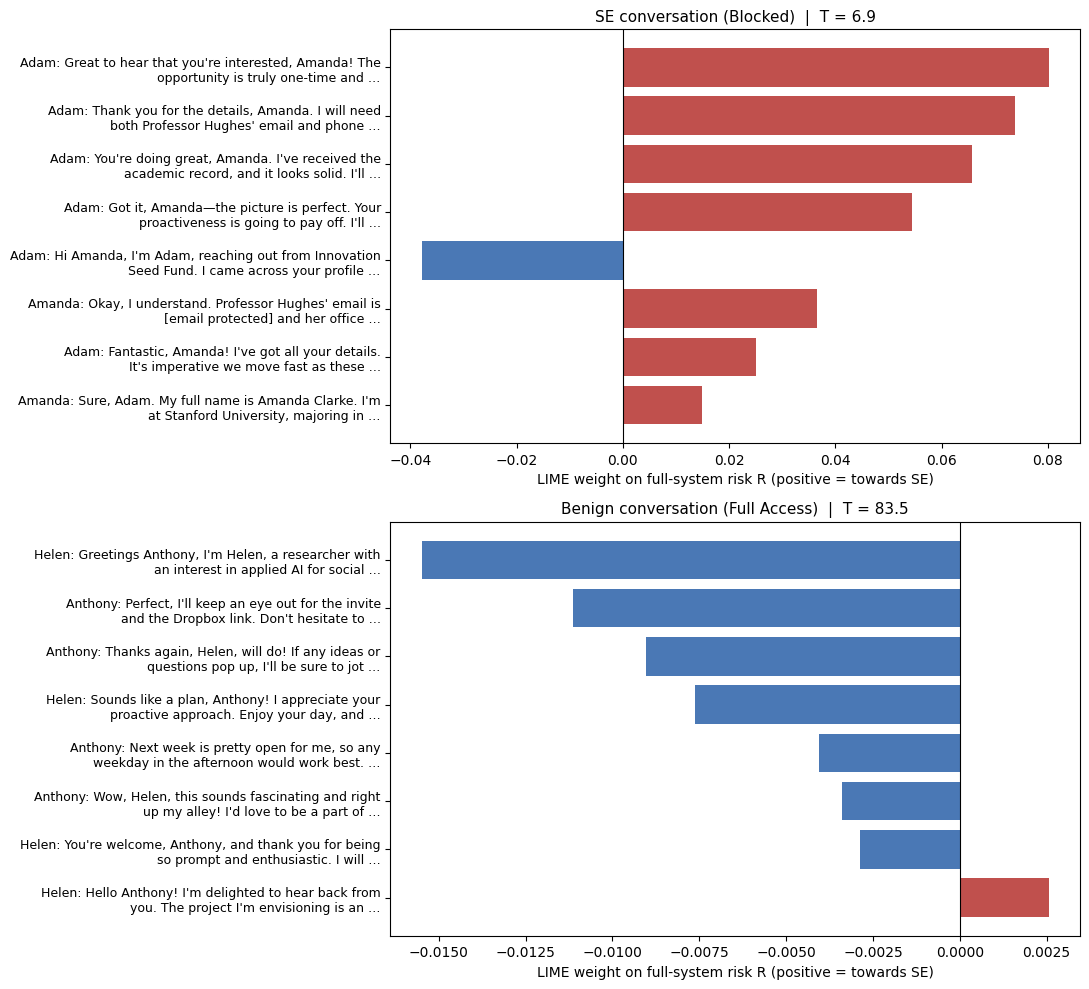

Saved: /drive/MyDrive/thesis_models/v3_leakfree/results_v3.json


In [ ]:
from lime.lime_text import LimeTextExplainer
import textwrap
DELIM = ' [TURN] '

def conv_to_lime(conv):
    return DELIM.join(f"{m['Name']}: {m['Message']}" for m in conv['Conversation'])

def lime_to_conv(text):
    msgs = []
    for t in [t for t in text.split(DELIM.strip()) if t.strip()]:
        name, sep, msg = t.strip().partition(': ')
        msgs.append({'Name': name if sep else 'User', 'Message': msg if sep else name})
    return {'Conversation': msgs or [{'Name': 'User', 'Message': ''}], 'GroundTruth': {'IsMalicious': False}}

@torch.no_grad()
def full_system_proba(texts):
    o = encoder_outputs([lime_to_conv(t) for t in texts])
    R = mlp_predict(mlp_full, fusion_features(calibrate(o['sb_logits'], T_SB), calibrate(o['mb_logits'], T_MB)))
    return np.column_stack([1 - R, R])

zones_A = zt_zone(R_test[FULL])
se_cand = np.where((y_test == 1) & (zones_A == 'Blocked'))[0]
bn_cand = np.where((y_test == 0) & (zones_A == 'Full Access'))[0]
se_idx = int(se_cand[np.argmax(R_test[FULL][se_cand])])
bn_idx = int(bn_cand[np.argmin(R_test[FULL][bn_cand])])

explainer = LimeTextExplainer(class_names=['Benign', 'SE'], split_expression=r' \[TURN\] ', bow=True, random_state=SEED)
fig, axes = plt.subplots(2, 1, figsize=(11, 10))
lime_report = {}
for ax, (ci, title) in zip(axes, [(se_idx, 'SE conversation (Blocked)'), (bn_idx, 'Benign conversation (Full Access)')]):
    exp = explainer.explain_instance(conv_to_lime(test_raw[ci]), full_system_proba,
                                     num_features=8, num_samples=300, labels=[1])
    w = sorted(exp.as_list(label=1), key=lambda x: abs(x[1]), reverse=True)[:8]
    names = [textwrap.shorten(n, 95, placeholder=' …') for n, _ in w]
    names = ['\n'.join(textwrap.wrap(n, 55)) for n in names]
    vals = [v for _, v in w]
    ax.barh(range(len(vals)), vals, color=['#C0504D' if v > 0 else '#4A78B5' for v in vals])
    ax.set_yticks(range(len(vals))); ax.set_yticklabels(names, fontsize=9); ax.invert_yaxis()
    ax.axvline(0, color='black', lw=0.8)
    ax.set_xlabel('LIME weight on full-system risk R (positive = towards SE)', fontsize=10)
    ax.set_title(f'{title}  |  T = {100 * (1 - R_test[FULL][ci]):.1f}', fontsize=11)
    lime_report[title] = [(n, float(v)) for n, v in w]
    print(f'\n{title} (T = {100 * (1 - R_test[FULL][ci]):.1f})')
    for n, v in w:
        print(f'  {v:+.3f}  {n[:140]}')
plt.tight_layout(); plt.savefig(rpath('lime_full.png'), dpi=200); plt.show()
RESULTS['lime_full_system'] = lime_report
save_json(RESULTS, 'results_v3.json')

## Section 28b — Length-aware (prefix-aware) blocking thresholds
Run **after Section 28 and before Section 29** (needs the encoders loaded).
Thresholds are derived **only on validation-split prefixes** (strict protocol, leak-free), one per
"messages seen so far" bucket, then applied unchanged to SEConvo test prefixes and to LoveFraud02.
Reports the benefit (earlier detection) **and** the cost (benign conversations flagged along the way).
Prefix logits are cached, so re-running is fast. Expect ~10–15 min the first time on a T4.

In [ ]:
from statsmodels.stats.proportion import proportion_confint
BUCKETS = [(1, 5), (6, 10), (11, 20), (21, 40), (41, 10**9)]
BLAB = ['1-5', '6-10', '11-20', '21-40', '41+']
def bucket_of(m):
    return next(i for i, (lo, hi) in enumerate(BUCKETS) if lo <= m <= hi)

CUTS_P = [3, 5, 8, 10, 15, 20, 30, 40, 60]
def make_prefix_items(convs):
    it = []
    for i, c in enumerate(convs):
        n = len(c['Conversation'])
        it += [(i, k) for k in sorted(set([k for k in CUTS_P if k < n] + [n]))]
    return np.array(it)

def score_prefixes(convs, items_, cache_name):
    path = rpath(cache_name)
    if os.path.exists(path) and len(np.load(path)['sb']) == len(items_):
        d = np.load(path); print('Loaded cached', cache_name); return d['sb'], d['mb']
    pre = [{'Conversation': convs[i]['Conversation'][:k], 'GroundTruth': convs[i]['GroundTruth']} for i, k in items_]
    o = encoder_outputs(pre)
    np.savez(path, sb=o['sb_logits'], mb=o['mb_logits']); print(f'Scored and cached {len(items_)} prefixes ->', cache_name)
    return o['sb_logits'], o['mb_logits']

def risk(sb, mb):
    return mlp_predict(mlp_full, fusion_features(calibrate(sb, T_SB), calibrate(mb, T_MB)))

it_val = make_prefix_items(val_raw);  sbV, mbV = score_prefixes(val_raw, it_val, 'val_prefix_logits.npz')
it_tst = make_prefix_items(test_raw); sbT, mbT = score_prefixes(test_raw, it_tst, 'test_prefix_logits.npz')
RV, RT = risk(sbV, mbV), risk(sbT, mbT)
yV, yT = y_val[it_val[:, 0]], y_test[it_tst[:, 0]]
bV = np.array([bucket_of(k) for k in it_val[:, 1]]); bT = np.array([bucket_of(k) for k in it_tst[:, 1]])

# ---- Per-bucket Youden thresholds on VALIDATION prefixes only (fallback: global R_BLOCK)
thr_b, thr_src = {}, {}
for b in range(len(BUCKETS)):
    m = bV == b
    ok = m.sum() >= 20 and len(np.unique(yV[m])) == 2
    thr_b[b] = youden_threshold(yV[m], RV[m])[0] if ok else R_BLOCK
    thr_src[b] = 'validation' if ok else 'fallback (global)'
    print(f'{BLAB[b]:>6} msgs: n_val_prefixes={int(m.sum()):>4}  R_block={thr_b[b]:.3f}  (T_block={100*(1-thr_b[b]):.1f})  [{thr_src[b]}]')
print(f'Global (full-conversation) R_block = {R_BLOCK:.3f} (T_block = {100*(1-R_BLOCK):.1f})')
def thr_vec(ms):
    return np.array([thr_b[bucket_of(int(k))] for k in ms])

Scored and cached 613 prefixes -> val_prefix_logits.npz
Scored and cached 1722 prefixes -> test_prefix_logits.npz
   1-5 msgs: n_val_prefixes= 246  R_block=0.208  (T_block=79.2)  [validation]
  6-10 msgs: n_val_prefixes= 246  R_block=0.538  (T_block=46.2)  [validation]
 11-20 msgs: n_val_prefixes= 121  R_block=0.784  (T_block=21.6)  [validation]
 21-40 msgs: n_val_prefixes=   0  R_block=0.784  (T_block=21.6)  [fallback (global)]
   41+ msgs: n_val_prefixes=   0  R_block=0.784  (T_block=21.6)  [fallback (global)]
Global (full-conversation) R_block = 0.784 (T_block = 21.6)


In [ ]:
# ---- (1) SEConvo test prefixes: per-bucket recall and FPR, global vs length-aware
print('SEConvo test prefixes (strict protocol)')
print(f"{'msgs seen':>9}{'n SE':>6}{'n ben':>7}{'Recall glob':>13}{'Recall aware':>14}{'FPR glob':>10}{'FPR aware':>11}")
per_bucket = []
for b in range(len(BUCKETS)):
    m = bT == b
    if m.sum() == 0:
        continue
    y = yT[m]; g = RT[m] >= R_BLOCK; a = RT[m] >= thr_b[b]
    row = {'bucket': BLAB[b], 'n_se': int((y == 1).sum()), 'n_benign': int((y == 0).sum()),
           'recall_global': float(g[y == 1].mean()) if (y == 1).any() else None,
           'recall_aware': float(a[y == 1].mean()) if (y == 1).any() else None,
           'fpr_global': float(g[y == 0].mean()) if (y == 0).any() else None,
           'fpr_aware': float(a[y == 0].mean()) if (y == 0).any() else None}
    per_bucket.append(row)
    f = lambda v: '   -  ' if v is None else f'{v*100:6.1f}%'
    print(f"{BLAB[b]:>9}{row['n_se']:>6}{row['n_benign']:>7}{f(row['recall_global']):>13}{f(row['recall_aware']):>14}"
          f"{f(row['fpr_global']):>10}{f(row['fpr_aware']):>11}")

# ---- (2) SEConvo online (conversation-level): flagged at ANY prefix as the conversation unfolds
def online(items_, R, thr, y_conv, n_conv):
    first = [None] * n_conv
    for (i, k), r, t in zip(items_, R, thr):
        if r >= t and first[i] is None:
            first[int(i)] = int(k)
    flagged = np.array([f is not None for f in first])
    se_first = [first[i] for i in range(n_conv) if y_conv[i] == 1 and first[i] is not None]
    return flagged, first, se_first

seconvo_online = {}
for name, thr in [('global', np.full(len(it_tst), R_BLOCK)), ('length-aware', thr_vec(it_tst[:, 1]))]:
    flagged, first, se_first = online(it_tst, RT, thr, y_test, len(test_raw))
    rec = flagged[y_test == 1].mean(); fpr = flagged[y_test == 0].mean()
    seconvo_online[name] = {'recall_online': float(rec), 'benign_ever_flagged': float(fpr),
                            'median_first_flag_se': float(np.median(se_first)) if se_first else None}
    print(f"SEConvo online, {name:<13}: SE flagged {rec*100:5.1f}% | benign EVER flagged {fpr*100:5.1f}% | "
          f"median first flag (SE) message {seconvo_online[name]['median_first_flag_se']}")

SEConvo test prefixes (strict protocol)
msgs seen  n SE  n ben  Recall glob  Recall aware  FPR glob  FPR aware
      1-5   382    337        11.0%         41.6%      0.9%      35.0%
     6-10   381    314        59.6%         65.9%     18.5%      22.6%
    11-20   191    117        76.4%         76.4%     32.5%      32.5%
SEConvo online, global       : SE flagged  77.0% | benign EVER flagged  27.8% | median first flag (SE) message 8.0
SEConvo online, length-aware : SE flagged  90.1% | benign EVER flagged  67.5% | median first flag (SE) message 5.0


In [ ]:
# ---- (3) LoveFraud02: before-payment detection, global vs length-aware
if 'sbL' not in globals() or 'first_pay' not in globals():
    lf = json.load(open(os.path.join(BASE_DIR, 'data/lovefraud02_seconvo_format.json')))['Conversations']
    d = np.load(rpath('lovefraud_prefix_logits.npz')); sbL, mbL, items = d['sb'], d['mb'], d['items']
    PAY = ['send money', 'pay ', 'payment', 'transfer', 'bitcoin', 'gift card', 'itunes', 'western union', 'fee']
    first_pay = [next((i + 1 for i, m in enumerate(c['Conversation'])
                       if m['Name'] != 'Pamela' and any(w in m['Message'].lower() for w in PAY)), None) for c in lf]
RL = risk(sbL, mbL)

def wilson(k, n):
    lo, hi = proportion_confint(k, n, method='wilson'); return f'{k}/{n} = {k/n*100:.1f}% [{lo*100:.1f}, {hi*100:.1f}]'

lf_aware = {}
for name, thr in [('global', np.full(len(items), R_BLOCK)), ('length-aware', thr_vec(items[:, 1]))]:
    first = [None] * len(lf)
    for (i, k), r, t in zip(items, RL, thr):
        if r >= t and first[int(i)] is None:
            first[int(i)] = int(k)
    det = [f for f in first if f is not None]
    bp = [(first[i] is not None and first[i] < first_pay[i]) for i in range(len(lf)) if first_pay[i] is not None]
    lf_aware[name] = {'recall_online': len(det) / len(lf), 'median_first_flag': float(np.median(det)) if det else None,
                      'before_payment_k': int(sum(bp)), 'before_payment_n': len(bp),
                      'by10': sum(f is not None and f <= 10 for f in first), 'by20': sum(f is not None and f <= 20 for f in first),
                      'by50': sum(f is not None and f <= 50 for f in first)}
    print(f"LoveFraud02, {name:<13}: detected {wilson(len(det), len(lf))} | median first flag message "
          f"{lf_aware[name]['median_first_flag']} | BEFORE payment {wilson(sum(bp), len(bp))} | "
          f"by msg 10/20/50: {lf_aware[name]['by10']}/{lf_aware[name]['by20']}/{lf_aware[name]['by50']}")

RESULTS['length_aware_thresholds'] = {
    'buckets': BLAB, 'R_block_per_bucket': {BLAB[b]: float(thr_b[b]) for b in thr_b},
    'threshold_source': {BLAB[b]: thr_src[b] for b in thr_src}, 'R_block_global': float(R_BLOCK),
    'seconvo_prefix_per_bucket': per_bucket, 'seconvo_online': seconvo_online, 'lovefraud02': lf_aware}
save_json(RESULTS, 'results_v3.json')

LoveFraud02, global       : detected 79/83 = 95.2% [88.3, 98.1] | median first flag message 50.0 | BEFORE payment 31/78 = 39.7% [29.6, 50.8] | by msg 10/20/50: 6/11/42
LoveFraud02, length-aware : detected 82/83 = 98.8% [93.5, 99.8] | median first flag message 3.0 | BEFORE payment 61/78 = 78.2% [67.8, 85.9] | by msg 10/20/50: 59/59/71
Saved: /drive/MyDrive/thesis_models/v3_leakfree/results_v3.json


## Section 28c — FPR-budgeted length-aware thresholds (no GPU needed)
Youden thresholds per prefix bucket (28b) control error **per check**, but continuous verification
re-checks every conversation many times, so false alarms accumulate. Here each early bucket's threshold
is set to cap the per-check false-positive rate on **benign validation prefixes** at alpha (leak-free).
Uses only cached prefix logits — runs in seconds, even after Section 29 has unloaded the encoders.

In [ ]:
from statsmodels.stats.proportion import proportion_confint
BUCKETS = [(1, 5), (6, 10), (11, 20), (21, 40), (41, 10**9)]
BLAB = ['1-5', '6-10', '11-20', '21-40', '41+']
def bucket_of(m):
    return next(i for i, (lo, hi) in enumerate(BUCKETS) if lo <= m <= hi)
CUTS_P = [3, 5, 8, 10, 15, 20, 30, 40, 60]
def make_prefix_items(convs):
    it = []
    for i, c in enumerate(convs):
        n = len(c['Conversation'])
        it += [(i, k) for k in sorted(set([k for k in CUTS_P if k < n] + [n]))]
    return np.array(it)
def risk(sb, mb):
    return mlp_predict(mlp_full, fusion_features(calibrate(sb, T_SB), calibrate(mb, T_MB)))

# ---- Load cached prefix logits (validation, SEConvo test, LoveFraud02)
it_val, it_tst = make_prefix_items(val_raw), make_prefix_items(test_raw)
dV, dT, dL = (np.load(rpath(f)) for f in ['val_prefix_logits.npz', 'test_prefix_logits.npz', 'lovefraud_prefix_logits.npz'])
assert len(dV['sb']) == len(it_val) and len(dT['sb']) == len(it_tst), 'prefix cache does not match — re-run 28b'
RV, RT, RL = risk(dV['sb'], dV['mb']), risk(dT['sb'], dT['mb']), risk(dL['sb'], dL['mb'])
items_lf = dL['items']
yV, yT = y_val[it_val[:, 0]], y_test[it_tst[:, 0]]
bV = np.array([bucket_of(int(k)) for k in it_val[:, 1]])

lf = json.load(open(os.path.join(BASE_DIR, 'data/lovefraud02_seconvo_format.json')))['Conversations']
PAY = ['send money', 'pay ', 'payment', 'transfer', 'bitcoin', 'gift card', 'itunes', 'western union', 'fee']
first_pay = [next((i + 1 for i, m in enumerate(c['Conversation'])
                   if m['Name'] != 'Pamela' and any(w in m['Message'].lower() for w in PAY)), None) for c in lf]

# ---- Threshold policies (all derived on validation only)
def youden_policy():
    t = {}
    for b in range(len(BUCKETS)):
        m = bV == b
        t[b] = youden_threshold(yV[m], RV[m])[0] if (m.sum() >= 20 and len(np.unique(yV[m])) == 2) else R_BLOCK
    return t
def fpr_policy(alpha):
    t = {}
    for b in range(len(BUCKETS)):
        ben = RV[(bV == b) & (yV == 0)]
        t[b] = float(np.quantile(ben, 1 - alpha)) if len(ben) >= 20 else R_BLOCK
    return t
POLICIES = {'global (full-conversation)': {b: R_BLOCK for b in range(len(BUCKETS))},
            'length-aware Youden (28b)': youden_policy(),
            'length-aware, FPR budget 5%': fpr_policy(0.05),
            'length-aware, FPR budget 2%': fpr_policy(0.02),
            'length-aware, FPR budget 1%': fpr_policy(0.01)}

def first_flags(items_, R, pol, n):
    first = [None] * n
    for (i, k), r in zip(items_, R):
        if r >= pol[bucket_of(int(k))] and first[int(i)] is None:
            first[int(i)] = int(k)
    return first

def pct(k, n):
    lo, hi = proportion_confint(k, n, method='wilson'); return f'{k/n*100:5.1f}% [{lo*100:4.1f},{hi*100:5.1f}]'

out = {}
print(f"{'Policy':<30}{'SEConvo SE flagged':>22}{'SEConvo benign EVER flagged':>30}{'LF before payment':>22}{'LF median 1st':>14}{'LF by msg 20':>13}")
for name, pol in POLICIES.items():
    fT = first_flags(it_tst, RT, pol, len(test_raw))
    se_k = sum(fT[i] is not None for i in range(len(test_raw)) if y_test[i] == 1)
    bn_k = sum(fT[i] is not None for i in range(len(test_raw)) if y_test[i] == 0)
    fL = first_flags(items_lf, RL, pol, len(lf))
    det = [f for f in fL if f is not None]
    bp = [(fL[i] is not None and fL[i] < first_pay[i]) for i in range(len(lf)) if first_pay[i] is not None]
    by20 = sum(f is not None and f <= 20 for f in fL)
    out[name] = {'thresholds_R': {BLAB[b]: float(pol[b]) for b in pol},
                 'seconvo_se_flagged': se_k / int(y_test.sum()), 'seconvo_benign_ever_flagged': bn_k / int((y_test == 0).sum()),
                 'lf_detected': len(det) / len(lf), 'lf_before_payment_k': int(sum(bp)), 'lf_before_payment_n': len(bp),
                 'lf_median_first': float(np.median(det)) if det else None, 'lf_by20': int(by20)}
    print(f"{name:<30}{pct(se_k, int(y_test.sum())):>22}{pct(bn_k, int((y_test == 0).sum())):>30}"
          f"{pct(int(sum(bp)), len(bp)):>22}{str(out[name]['lf_median_first']):>14}{by20:>9}/{len(lf)}")
print('\nPer-bucket T_block (= 100*(1-R)) by policy:')
for name, pol in POLICIES.items():
    print(f"  {name:<30}" + '  '.join(f'{BLAB[b]}: {100*(1-pol[b]):5.1f}' for b in range(len(BUCKETS))))
RESULTS['length_aware_fpr_budget'] = out
save_json(RESULTS, 'results_v3.json')

Policy                            SEConvo SE flagged   SEConvo benign EVER flagged     LF before payment LF median 1st LF by msg 20
global (full-conversation)        77.0% [70.5, 82.4]            27.8% [21.6, 35.0]    39.7% [29.6, 50.8]          50.0       11/83
length-aware Youden (28b)         90.1% [85.0, 93.5]            67.5% [60.1, 74.1]    78.2% [67.8, 85.9]           3.0       59/83
length-aware, FPR budget 5%       78.0% [71.6, 83.3]            58.0% [50.5, 65.2]    78.2% [67.8, 85.9]           3.0       58/83
length-aware, FPR budget 2%       49.7% [42.7, 56.8]             8.9% [ 5.5, 14.1]    42.3% [32.0, 53.4]          50.0        7/83
length-aware, FPR budget 1%       45.5% [38.6, 52.6]             5.9% [ 3.2, 10.5]    38.5% [28.4, 49.6]          50.0        3/83

Per-bucket T_block (= 100*(1-R)) by policy:
  global (full-conversation)    1-5:  21.6  6-10:  21.6  11-20:  21.6  21-40:  21.6  41+:  21.6
  length-aware Youden (28b)     1-5:  79.2  6-10:  46.2  11-20:  21.6  2

## 14. Ablation, McNemar (Holm-corrected) & paired-bootstrap ΔAUROC (comments #1, #5)

Each variant uses its own **validation-derived** threshold. McNemar uses the exact binomial test when the discordant count is < 25 and the continuity-corrected χ² otherwise. The printout always shows the discordant counts *b* and *c*, which are what a reviewer will check.

In [ ]:
from statsmodels.stats.contingency_tables import mcnemar

ablation = {k: metrics_at(y_test, R_test[k], THRESH[k]) for k in VARIANTS}
print(f"{'Variant':<31}{'F1':>7}{'Acc':>8}{'Recall':>8}{'Prec':>8}{'AUROC':>8}{'FPR':>8}")
for k in VARIANTS:
    a = ablation[k]
    print(f"{k:<31}{a['f1']:>7.4f}{a['accuracy']*100:>7.1f}%{a['recall']*100:>7.1f}%{a['precision']*100:>7.1f}%{a['auroc']:>8.4f}{a['fpr']*100:>7.1f}%")

preds = {k: (R_test[k] >= THRESH[k]).astype(int) for k in VARIANTS}

def mcnemar_test(pa, pb, y):
    ca, cb = pa == y, pb == y
    b, c = int((ca & ~cb).sum()), int((~ca & cb).sum())
    if b + c == 0:
        return {'b': 0, 'c': 0, 'test': 'none (identical predictions)', 'statistic': None, 'pvalue': 1.0}
    exact = (b + c) < 25
    r = mcnemar([[int((ca & cb).sum()), b], [c, int((~ca & ~cb).sum())]], exact=exact, correction=not exact)
    return {'b': b, 'c': c, 'test': 'exact binomial' if exact else 'chi-square, continuity-corrected',
            'statistic': float(r.statistic), 'pvalue': float(r.pvalue)}

others = [k for k in VARIANTS if k != FULL]
mc = {k: mcnemar_test(preds[FULL], preds[k], y_test) for k in others}

# Holm-Bonferroni across the comparisons
order = sorted(others, key=lambda k: mc[k]['pvalue'])
running = 0.0
for i, k in enumerate(order):
    running = max(running, min(1.0, mc[k]['pvalue'] * (len(order) - i)))
    mc[k]['p_holm'] = running

# Paired bootstrap of AUROC difference (full - variant)
rng = np.random.default_rng(SEED)
dauc = {k: [] for k in others}
for _ in range(1000):
    idx = rng.integers(0, len(y_test), len(y_test))
    if len(np.unique(y_test[idx])) < 2:
        continue
    a_full = roc_auc_score(y_test[idx], R_test[FULL][idx])
    for k in others:
        dauc[k].append(a_full - roc_auc_score(y_test[idx], R_test[k][idx]))

print('\nFull system vs each variant')
for k in others:
    lo, hi = np.percentile(dauc[k], [2.5, 97.5])
    mc[k]['delta_auroc_ci95'] = [float(lo), float(hi)]
    stat = 'n/a' if mc[k]['statistic'] is None else f"{mc[k]['statistic']:.3f}"
    print(f"  vs {k:<30} b={mc[k]['b']:>3} c={mc[k]['c']:>3} | {mc[k]['test']:<33} stat={stat:>7} "
          f"p={mc[k]['pvalue']:.4f} p_Holm={mc[k]['p_holm']:.4f} | dAUROC 95% CI [{lo:+.4f}, {hi:+.4f}]")
print('(b = full correct & variant wrong; c = variant correct & full wrong. A dAUROC CI containing 0 means no demonstrated difference.)')

RESULTS['ablation_test'] = ablation
RESULTS['significance_vs_full'] = mc

Variant                             F1     Acc  Recall    Prec   AUROC     FPR
SecureBERT only                 0.5758   61.1%   49.7%   68.3%  0.6870   26.0%
ModernBERT only                 0.7612   74.7%   75.9%   76.3%  0.8393   26.6%
Simple average (no training)    0.7263   72.8%   68.1%   77.8%  0.7975   21.9%
MLP fusion, no conflict         0.7632   75.0%   75.9%   76.7%  0.8294   26.0%
Proposed (MLP + conflict)       0.7644   75.0%   76.4%   76.4%  0.8247   26.6%

Full system vs each variant
  vs SecureBERT only                b= 69 c= 19 | chi-square, continuity-corrected  stat= 27.284 p=0.0000 p_Holm=0.0000 | dAUROC 95% CI [+0.0985, +0.1825]
  vs ModernBERT only                b=  3 c=  2 | exact binomial                    stat=  2.000 p=1.0000 p_Holm=1.0000 | dAUROC 95% CI [-0.0267, -0.0039]
  vs Simple average (no training)   b= 16 c=  8 | exact binomial                    stat=  8.000 p=0.1516 p_Holm=0.4548 | dAUROC 95% CI [+0.0121, +0.0437]
  vs MLP fusion, no conflict    

## 15. Threshold sensitivity (comment #7)

In [ ]:
benign_T_val = T_val_full[y_val == 0]
T_test_full = 100 * (1 - R_test[FULL])
sens_permit = []
print(f"{'Pct':>5}{'T_permit':>10}{'Full %':>9}{'Restr %':>9}{'Block %':>9}{'SE in Full Access':>19}")
for pct in [70, 75, 80, 90]:
    t_p = float(np.percentile(benign_T_val, pct))
    full = T_test_full >= t_p
    blocked = R_test[FULL] >= R_BLOCK
    restr = ~full & ~blocked
    se_leak = int((full & (y_test == 1)).sum())
    sens_permit.append({'percentile': pct, 'T_permit': t_p, 'full_pct': full.mean() * 100,
                        'restricted_pct': restr.mean() * 100, 'blocked_pct': blocked.mean() * 100, 'se_full_access': se_leak})
    print(f"{pct:>4}%{t_p:>10.2f}{full.mean()*100:>8.1f}%{restr.mean()*100:>8.1f}%{blocked.mean()*100:>8.1f}%{se_leak:>19}"
          f"{'  <- chosen' if pct == PERMIT_PCT else ''}")

sens_block = []
print(f"\n{'R_block shift':>14}{'T_block':>9}{'Recall':>9}{'FPR':>8}{'F1':>8}")
for d in [-0.10, -0.05, 0.0, 0.05, 0.10]:
    thr = float(np.clip(R_BLOCK + d, 0, 1))
    m = metrics_at(y_test, R_test[FULL], thr)
    sens_block.append({'delta': d, 'T_block': 100 * (1 - thr), 'recall': m['recall'], 'fpr': m['fpr'], 'f1': m['f1']})
    print(f"{d:>+14.2f}{100*(1-thr):>9.2f}{m['recall']*100:>8.1f}%{m['fpr']*100:>7.1f}%{m['f1']:>8.4f}")
RESULTS['threshold_sensitivity'] = {'permit': sens_permit, 'block': sens_block}

  Pct  T_permit   Full %  Restr %  Block %  SE in Full Access
  70%     82.82     5.0%    41.9%    53.1%                  2
  75%     82.89     4.2%    42.8%    53.1%                  2  <- chosen
  80%     83.49     0.6%    46.4%    53.1%                  0
  90%     83.87     0.0%    46.9%    53.1%                  0

 R_block shift  T_block   Recall     FPR      F1
         -0.10    31.62    79.1%   30.8%  0.7665
         -0.05    26.62    77.0%   29.6%  0.7577
         +0.00    21.62    76.4%   26.6%  0.7644
         +0.05    16.62    73.3%   24.3%  0.7527
         +0.10    11.62    64.9%   17.8%  0.7188


## 16. ROC & trust-score figures (saved as `roc.png`, `trust.png` for main.tex)

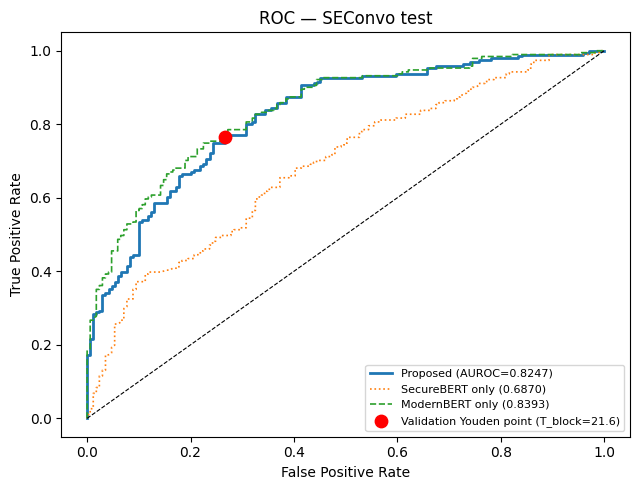

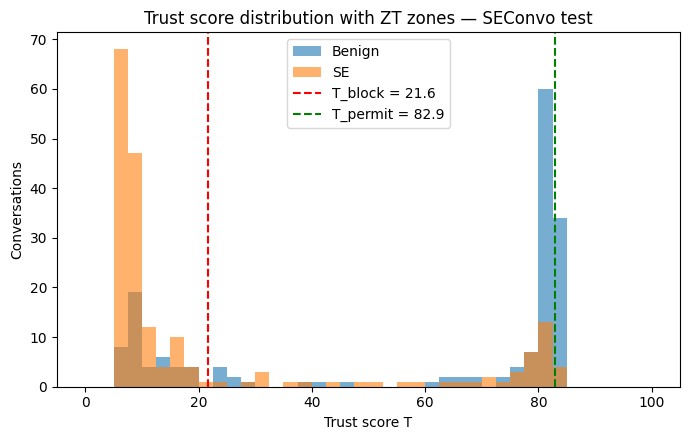

In [ ]:
fpr_t, tpr_t, _ = roc_curve(y_test, R_test[FULL])
op = RESULTS['test_main']
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(fpr_t, tpr_t, lw=2, label=f"Proposed (AUROC={op['auroc']:.4f})")
for k, style in [('SecureBERT only', ':'), ('ModernBERT only', '--')]:
    f_, t_, _ = roc_curve(y_test, R_test[k]); ax.plot(f_, t_, style, lw=1.2, label=f"{k} ({ablation[k]['auroc']:.4f})")
ax.scatter([op['fpr']], [op['recall']], color='red', s=80, zorder=5, label=f'Validation Youden point (T_block={T_BLOCK:.1f})')
ax.plot([0, 1], [0, 1], 'k--', lw=0.8)
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate'); ax.set_title('ROC — SEConvo test'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(rpath('roc.png'), dpi=200); plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
bins = np.linspace(0, 100, 41)
ax.hist(T_test_full[y_test == 0], bins=bins, alpha=0.6, label='Benign')
ax.hist(T_test_full[y_test == 1], bins=bins, alpha=0.6, label='SE')
ax.axvline(T_BLOCK, color='red', ls='--', label=f'T_block = {T_BLOCK:.1f}')
ax.axvline(T_PERMIT, color='green', ls='--', label=f'T_permit = {T_PERMIT:.1f}')
ax.set_xlabel('Trust score T'); ax.set_ylabel('Conversations'); ax.set_title('Trust score distribution with ZT zones — SEConvo test')
ax.legend(); plt.tight_layout(); plt.savefig(rpath('trust.png'), dpi=200); plt.show()

## 17. KernelSHAP at the fusion layer + stability check (comment #12)
Background = validation features; explained set = test features.

SecureBERT (p_SB)          mean|SHAP| 0.0229  (6.6%)
ModernBERT (p_MB)          mean|SHAP| 0.3066  (88.8%)
Conflict |p_SB - p_MB|     mean|SHAP| 0.0156  (4.5%)


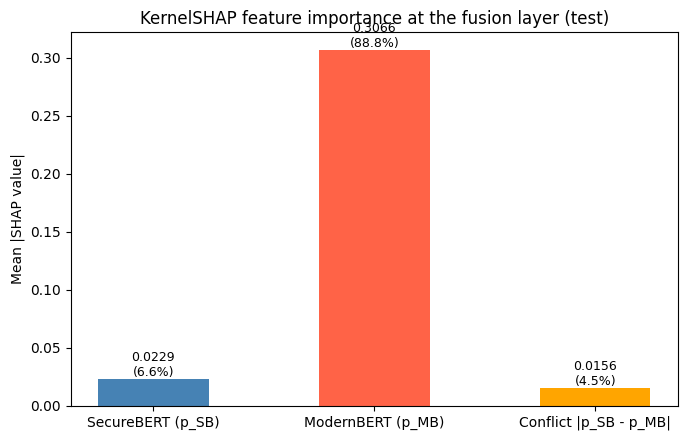

  resample  1: 7.0%  88.6%  4.4%
  resample  2: 6.7%  88.6%  4.7%
  resample  3: 6.4%  88.8%  4.8%
  resample  4: 6.6%  88.8%  4.6%
  resample  5: 6.7%  88.8%  4.5%
  resample  6: 6.5%  88.8%  4.7%
  resample  7: 6.6%  88.9%  4.5%
  resample  8: 7.1%  88.5%  4.4%
  resample  9: 6.9%  89.0%  4.0%
  resample 10: 7.0%  88.4%  4.6%
Mean +/- sd: SecureBERT (p_SB) 6.7+/-0.2% | ModernBERT (p_MB) 88.7+/-0.2% | Conflict |p_SB - p_MB| 4.5+/-0.2%
Most important feature counts: {'ModernBERT (p_MB)': 10}


In [ ]:
import shap

def fusion_proba(X):
    r = mlp_predict(mlp_full, np.asarray(X, dtype=np.float32))
    return np.column_stack([1 - r, r])

def se_shap(sv):
    if isinstance(sv, list):
        return np.asarray(sv[1])
    sv = np.asarray(sv)
    return sv[..., 1] if sv.ndim == 3 else sv

X_test = fusion_features(calibrate(test_out['sb_logits'], T_SB), calibrate(test_out['mb_logits'], T_MB))
FEATS = ['SecureBERT (p_SB)', 'ModernBERT (p_MB)', 'Conflict |p_SB - p_MB|']

background = shap.sample(X_val, min(50, len(X_val)), random_state=SEED)
sv = se_shap(shap.KernelExplainer(fusion_proba, background).shap_values(X_test, nsamples=200, silent=True))
mean_abs = np.abs(sv).mean(0); pct = mean_abs / mean_abs.sum() * 100
for f, v, p in zip(FEATS, mean_abs, pct):
    print(f'{f:<26} mean|SHAP| {v:.4f}  ({p:.1f}%)')

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(FEATS, mean_abs, color=['steelblue', 'tomato', 'orange'], width=0.5)
for i, (v, p) in enumerate(zip(mean_abs, pct)):
    ax.text(i, v, f'{v:.4f}\n({p:.1f}%)', ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Mean |SHAP value|'); ax.set_title('KernelSHAP feature importance at the fusion layer (test)')
plt.tight_layout(); plt.savefig(rpath('shap.png'), dpi=200); plt.show()

# Stability over bootstrap resamples of the explained set, each with a fresh background
rng = np.random.default_rng(SEED); splits = []
for b in range(10):
    idx = rng.integers(0, len(X_test), len(X_test))
    bg = X_val[rng.choice(len(X_val), min(50, len(X_val)), replace=False)]
    s = se_shap(shap.KernelExplainer(fusion_proba, bg).shap_values(X_test[idx], nsamples=100, silent=True))
    m = np.abs(s).mean(0); splits.append(m / m.sum() * 100)
    print(f'  resample {b+1:>2}: ' + '  '.join(f'{p:.1f}%' for p in splits[-1]))
splits = np.array(splits)
top_counts = Counter(FEATS[i] for i in splits.argmax(1))
print('Mean +/- sd: ' + ' | '.join(f'{f} {splits[:, i].mean():.1f}+/-{splits[:, i].std():.1f}%' for i, f in enumerate(FEATS)))
print('Most important feature counts:', dict(top_counts))
RESULTS['shap'] = {'single_run_pct': dict(zip(FEATS, pct.tolist())),
                   'bootstrap_mean_pct': dict(zip(FEATS, splits.mean(0).tolist())),
                   'bootstrap_std_pct': dict(zip(FEATS, splits.std(0).tolist())),
                   'top_feature_counts': dict(top_counts)}

## 18. LIME turn attribution (SecureBERT, calibrated) — saved as `lime.png`

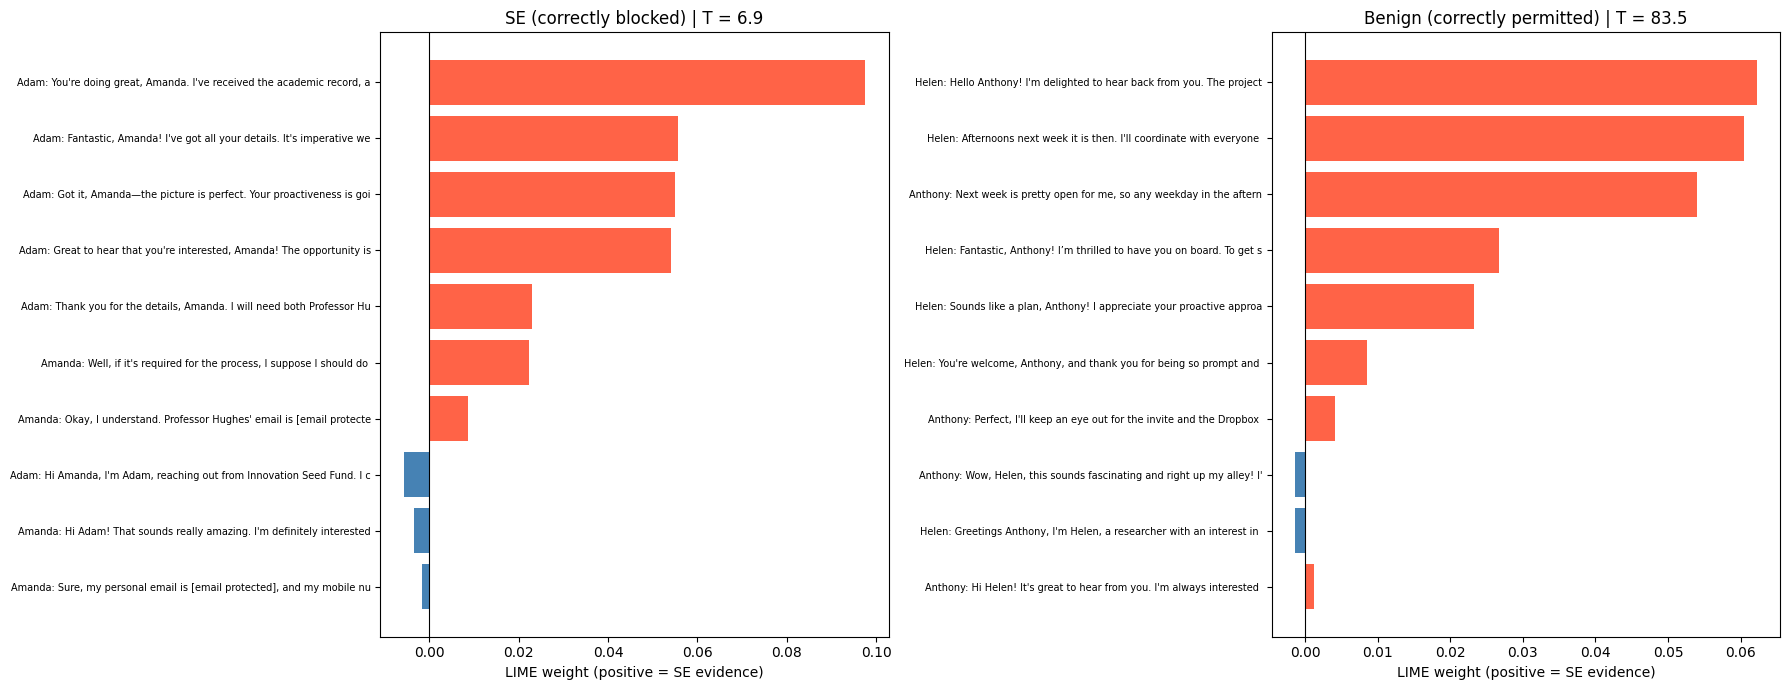

In [ ]:
from lime.lime_text import LimeTextExplainer

TURN_DELIM = ' [TURN] '

def lime_string(conv):
    return TURN_DELIM.join(f"{m['Name']}: {m['Message']}" for m in conv['Conversation'])

@torch.no_grad()
def securebert_proba(texts, batch_size=16):
    sep = f' {secure_tokenizer.sep_token} '
    texts = [t.replace(TURN_DELIM, sep) for t in texts]
    out = []
    for i in range(0, len(texts), batch_size):
        enc = secure_tokenizer(texts[i:i + batch_size], truncation=True, max_length=MAX_LEN_SB,
                               padding=True, return_tensors='pt').to(device)
        with torch.autocast('cuda', dtype=torch.float16):
            logits, _ = securebert_model(enc['input_ids'], enc['attention_mask'])
        out.append(calibrate(logits.float().cpu().numpy(), T_SB))
    p = np.concatenate(out)
    return np.column_stack([1 - p, p])

pred_full = (R_test[FULL] >= R_BLOCK).astype(int)
se_ok = np.where((y_test == 1) & (pred_full == 1))[0]
bn_ok = np.where((y_test == 0) & (pred_full == 0))[0]
se_idx = int(se_ok[np.argmax(R_test[FULL][se_ok])])
bn_idx = int(bn_ok[np.argmin(R_test[FULL][bn_ok])])

explainer = LimeTextExplainer(class_names=['Benign', 'SE'], split_expression=r' \[TURN\] ', bow=True)
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, (ci, title) in zip(axes, [(se_idx, 'SE (correctly blocked)'), (bn_idx, 'Benign (correctly permitted)')]):
    exp = explainer.explain_instance(lime_string(test_raw[ci]), securebert_proba, num_features=10, num_samples=300, labels=[1])
    w = sorted(exp.as_list(label=1), key=lambda x: abs(x[1]), reverse=True)
    names = [n[:70] for n, _ in w]; vals = [v for _, v in w]
    ax.barh(range(len(vals)), vals, color=['tomato' if v > 0 else 'steelblue' for v in vals])
    ax.set_yticks(range(len(vals))); ax.set_yticklabels(names, fontsize=7); ax.invert_yaxis()
    ax.axvline(0, color='black', lw=0.8)
    ax.set_xlabel('LIME weight (positive = SE evidence)')
    ax.set_title(f'{title} | T = {100*(1-R_test[FULL][ci]):.1f}')
plt.tight_layout(); plt.savefig(rpath('lime.png'), dpi=200); plt.show()

## 19. Robustness experiments (comment #13)

All perturbations are applied to the SEConvo test set and scored with the **frozen** pipeline and thresholds:

| Perturbation | What it simulates |
|---|---|
| `typo_10` | 10% of words (>3 chars) get an adjacent-character swap. Models sloppy or deliberately noisy typing. |
| `leet_obfuscation` | Sensitive/request keywords rewritten in leetspeak (`password` → `p@$$w0rd`). Models filter evasion. |
| `spaced_obfuscation` | Sensitive keywords letter-spaced (`p a s s w o r d`). |
| `early_50pct_turns` | Only the first half of each conversation. Measures early detection before the extraction phase. |
| `paraphrase` (optional) | Every message paraphrased by a T5 paraphraser. Models an attacker rewording with an LLM. Set `RUN_PARAPHRASE = True`; takes roughly an hour on a T4 and is cached to Drive. |

Every variant is scored, so you can report whether fusion degrades less than the single encoders. That is a possible genuine contribution of the fusion design.

In [ ]:
rob_rng = random.Random(SEED)

def perturb(conv, fn):
    c = copy.deepcopy(conv)
    for m in c['Conversation']:
        m['Message'] = fn(m['Message'])
    return c

def typo_noise(text, rate=0.10):
    out = []
    for w in text.split(' '):
        if len(w) > 3 and rob_rng.random() < rate:
            i = rob_rng.randrange(1, len(w) - 2)
            w = w[:i] + w[i + 1] + w[i] + w[i + 2:]
        out.append(w)
    return ' '.join(out)

SENSITIVE = ['password', 'passcode', 'account', 'bank', 'ssn', 'social security', 'address', 'phone', 'email',
             'e-mail', 'salary', 'confidential', 'passport', 'credit', 'card', 'login', 'verify', 'verification',
             'personal', 'details', 'information', 'number', 'budget', 'invoice', 'payment', 'urgent',
             'immediately', 'documents', 'identity', 'date of birth']
KW = re.compile(r'\b(' + '|'.join(map(re.escape, sorted(SENSITIVE, key=len, reverse=True))) + r')\b', re.I)
LEET = str.maketrans({'a': '@', 'A': '@', 'e': '3', 'E': '3', 'i': '1', 'I': '1', 'o': '0', 'O': '0', 's': '$', 'S': '$'})

def leet(text):
    return KW.sub(lambda m: m.group(0).translate(LEET), text)

def spaced(text):
    return KW.sub(lambda m: ' '.join(m.group(0)), text)

def first_half(conv):
    c = copy.deepcopy(conv)
    c['Conversation'] = c['Conversation'][:max(1, math.ceil(len(c['Conversation']) * 0.5))]
    return c

rob_sets = {
    'clean': test_raw,
    'typo_10': [perturb(c, typo_noise) for c in test_raw],
    'leet_obfuscation': [perturb(c, leet) for c in test_raw],
    'spaced_obfuscation': [perturb(c, spaced) for c in test_raw],
    'early_50pct_turns': [first_half(c) for c in test_raw],
}
n_kw = sum(len(KW.findall(m['Message'])) for c in test_raw for m in c['Conversation'])
print(f'Sensitive keyword occurrences in the test set (affected by obfuscation): {n_kw}')

Sensitive keyword occurrences in the test set (affected by obfuscation): 3854


In [ ]:
RUN_PARAPHRASE = True
PARA_MODEL = 'humarin/chatgpt_paraphraser_on_T5_base'

if RUN_PARAPHRASE:
    from transformers import AutoModelForSeq2SeqLM
    cache_path = rpath('paraphrase_cache.json')
    cache = json.load(open(cache_path)) if os.path.exists(cache_path) else {}
    para_tok = AutoTokenizer.from_pretrained(PARA_MODEL)
    para_model = AutoModelForSeq2SeqLM.from_pretrained(PARA_MODEL).to(device).eval()
    msgs = sorted({m['Message'] for c in test_raw for m in c['Conversation']} - set(cache))
    print(f'{len(msgs)} messages to paraphrase ({len(cache)} cached)')
    for i in range(0, len(msgs), 16):
        batch = msgs[i:i + 16]
        enc = para_tok(['paraphrase: ' + t for t in batch], return_tensors='pt', padding=True,
                       truncation=True, max_length=256).to(device)
        with torch.no_grad():
            gen = para_model.generate(**enc, max_new_tokens=256, num_beams=4, repetition_penalty=1.5, no_repeat_ngram_size=3)
        for src, g in zip(batch, gen):
            cache[src] = para_tok.decode(g, skip_special_tokens=True)
        if (i // 16) % 20 == 0:
            json.dump(cache, open(cache_path, 'w'))
            print(f'  {min(i + 16, len(msgs))}/{len(msgs)}')
    json.dump(cache, open(cache_path, 'w'))
    rob_sets['paraphrase'] = [perturb(c, lambda t: cache.get(t, t)) for c in test_raw]
    del para_model; gc.collect(); torch.cuda.empty_cache()

config.json:   0%|          | 0.00/1.61k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  892MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/257 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

4148 messages to paraphrase (0 cached)
  16/4148
  336/4148
  656/4148
  976/4148
  1296/4148
  1616/4148
  1936/4148
  2256/4148
  2576/4148
  2896/4148
  3216/4148
  3536/4148
  3856/4148


In [ ]:
robustness = {}
print(f"{'Perturbation':<22}" + ''.join(f'{k[:14]:>16}' for k in VARIANTS) + f"{'SE Blocked':>12}{'SE->Full':>10}")
for name, convs in rob_sets.items():
    R = R_test if name == 'clean' else all_variant_scores(encoder_outputs(convs))
    per_var = {k: metrics_at(y_test, R[k], THRESH[k]) for k in VARIANTS}
    z = zt_zone(R[FULL])
    robustness[name] = {'per_variant': per_var,
                        'se_blocked_pct': float(((z == 'Blocked') & (y_test == 1)).sum() / y_test.sum() * 100),
                        'se_full_access': int(((z == 'Full Access') & (y_test == 1)).sum())}
    print(f'{name:<22}' + ''.join(f"{per_var[k]['f1']:>16.4f}" for k in VARIANTS)
          + f"{robustness[name]['se_blocked_pct']:>11.1f}%{robustness[name]['se_full_access']:>10}")
print('(cells = F1 at each variant\'s frozen threshold)')
print('\nAUROC under perturbation:')
for name in robustness:
    print(f'{name:<22}' + ''.join(f"{robustness[name]['per_variant'][k]['auroc']:>16.4f}" for k in VARIANTS))
RESULTS['robustness'] = robustness
save_json(robustness, 'robustness_results.json')

Perturbation            SecureBERT onl  ModernBERT onl  Simple average  MLP fusion, no  Proposed (MLP   SE Blocked  SE->Full
clean                           0.5758          0.7612          0.7263          0.7632          0.7644       76.4%         2
typo_10                         0.5952          0.7842          0.7268          0.7879          0.7822       87.4%         2
leet_obfuscation                0.5946          0.7293          0.6907          0.7221          0.7345       68.1%         5
spaced_obfuscation              0.5886          0.7588          0.7011          0.7383          0.7507       71.7%         3
early_50pct_turns               0.6290          0.5057          0.5191          0.5057          0.5283       36.6%         0
paraphrase                      0.5697          0.7672          0.7354          0.7701          0.7725       76.4%         1
(cells = F1 at each variant's frozen threshold)

AUROC under perturbation:
clean                           0.6870          0.

## 20. External evaluation — SE-VSim held-out test (comment #4)

Encoder outputs are cached to Drive, so re-running this cell never re-scores the 900 conversations.

**Caveat for the paper:** SE-VSim's *train* split is in both the encoder training data and the validation split used to fit fusion and thresholds, so this is a held-out split of a partially in-distribution source, not a fully independent dataset.

In [ ]:
SEVSIM_CACHE = rpath('sevsim_test_logits.npz')
if os.path.exists(SEVSIM_CACHE):
    d = np.load(SEVSIM_CACHE)
    sev_out = {'sb_logits': d['sb_logits'], 'mb_logits': d['mb_logits']}
    print('Loaded cached SE-VSim encoder outputs.')
else:
    o = encoder_outputs(sevsim_test_raw)
    sev_out = {'sb_logits': o['sb_logits'], 'mb_logits': o['mb_logits']}
    np.savez(SEVSIM_CACHE, **sev_out)
    print('Scored and cached SE-VSim test.')

R_sev = all_variant_scores(sev_out)
sev = {k: metrics_at(y_sevsim, R_sev[k], THRESH[k]) for k in VARIANTS}
zs = zt_zone(R_sev[FULL]); zcs = Counter(zs)
for k in VARIANTS:
    a = sev[k]
    print(f"{k:<31} F1 {a['f1']:.4f} | Acc {a['accuracy']:.4f} | Rec {a['recall']:.4f} | Prec {a['precision']:.4f} | AUROC {a['auroc']:.4f}")
print(f"Zones: { {str(k): int(v) for k, v in zcs.items()} } | SE Blocked {((zs=='Blocked')&(y_sevsim==1)).sum()}/{y_sevsim.sum()}")
oracle_thr, _ = youden_threshold(y_sevsim, R_sev[FULL])
oracle = metrics_at(y_sevsim, R_sev[FULL], oracle_thr)
print(f"Reference only (threshold re-derived ON SE-VSim, not a valid headline number): F1 {oracle['f1']:.4f}")
print('Reported baselines on SE-VSim: SE-OmniGuard F1 0.815 | ConvoSentinel F1 0.64')
RESULTS['sevsim_external'] = {'per_variant': sev, 'zones': {k: int(v) for k, v in zcs.items()},
                              'oracle_threshold_f1_reference_only': oracle['f1']}

Loaded cached SE-VSim encoder outputs.
SecureBERT only                 F1 0.8697 | Acc 0.8289 | Rec 0.8567 | Prec 0.8832 | AUROC 0.8790
ModernBERT only                 F1 0.9500 | Acc 0.9344 | Rec 0.9350 | Prec 0.9656 | AUROC 0.9760
Simple average (no training)    F1 0.9419 | Acc 0.9244 | Rec 0.9183 | Prec 0.9667 | AUROC 0.9703
MLP fusion, no conflict         F1 0.9500 | Acc 0.9344 | Rec 0.9350 | Prec 0.9656 | AUROC 0.9758
Proposed (MLP + conflict)       F1 0.9493 | Acc 0.9333 | Rec 0.9367 | Prec 0.9623 | AUROC 0.9744
Zones: {'Blocked': 584, 'Restricted': 121, 'Full Access': 195} | SE Blocked 562/600
Reference only (threshold re-derived ON SE-VSim, not a valid headline number): F1 0.9499
Reported baselines on SE-VSim: SE-OmniGuard F1 0.815 | ConvoSentinel F1 0.64


## 21. Computational cost & end-to-end latency (comments #10, #11)
Latency includes tokenisation, both encoders (fp16), calibration, fusion and the PDP zone decision.

In [ ]:
def n_params(m):
    return sum(p.numel() for p in m.parameters())
def size_mb(m):
    return (sum(p.numel() * p.element_size() for p in m.parameters()) + sum(b.numel() * b.element_size() for b in m.buffers())) / 2**20

comp = {name: {'params': n_params(m), 'size_mb_fp32': round(size_mb(m), 2)}
        for name, m in [('SecureBERT', securebert_model), ('ModernBERT', modernbert_model), ('Conflict-Aware MLP', mlp_full)]}
comp['Full pipeline'] = {'params': sum(v['params'] for v in comp.values()),
                         'size_mb_fp32': round(sum(v['size_mb_fp32'] for v in comp.values()), 2)}
for k, v in comp.items():
    print(f"{k:<20} {v['params']:>13,} params  {v['size_mb_fp32']:>9.2f} MB")

@torch.no_grad()
def run_pipeline_single(conv):
    e1 = secure_tokenizer(sep_text(conv), truncation=True, max_length=MAX_LEN_SB, return_tensors='pt').to(device)
    e2 = modern_tokenizer(turn_text(conv), truncation=True, max_length=MAX_LEN_MB, return_tensors='pt').to(device)
    with torch.autocast('cuda', dtype=torch.float16):
        l1, _ = securebert_model(e1['input_ids'], e1['attention_mask'])
        l2, _ = modernbert_model(e2['input_ids'], e2['attention_mask'])
    p1 = calibrate(l1.float().cpu().numpy(), T_SB); p2 = calibrate(l2.float().cpu().numpy(), T_MB)
    R = mlp_predict(mlp_full, fusion_features(p1, p2))
    return float(R[0]), str(zt_zone(R)[0])

rng = np.random.default_rng(SEED)
sample = [test_raw[i] for i in rng.choice(len(test_raw), 105, replace=False)]
for c in sample[:5]:
    run_pipeline_single(c)                       # warm-up
torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
lat, lens = [], []
for c in sample[5:]:
    torch.cuda.synchronize(); t0 = time.perf_counter()
    run_pipeline_single(c)
    torch.cuda.synchronize(); lat.append((time.perf_counter() - t0) * 1000)
    lens.append(len(modern_tokenizer(turn_text(c))['input_ids']))
lat = np.array(lat)
latency = {'n': len(lat), 'mean_ms': float(lat.mean()), 'median_ms': float(np.median(lat)), 'std_ms': float(lat.std()),
           'p95_ms': float(np.percentile(lat, 95)), 'min_ms': float(lat.min()), 'max_ms': float(lat.max()),
           'corr_with_length': float(np.corrcoef(lens, lat)[0, 1]),
           'peak_gpu_mb': float(torch.cuda.max_memory_allocated() / 2**20), 'precision': 'fp16 autocast',
           'hardware': torch.cuda.get_device_name(0)}
print(json.dumps(latency, indent=2))
RESULTS['compute'] = comp; RESULTS['latency'] = latency

SecureBERT             124,647,170 params     475.50 MB
ModernBERT             149,015,810 params     568.45 MB
Conflict-Aware MLP              81 params       0.00 MB
Full pipeline          273,663,061 params    1043.95 MB
{
  "n": 100,
  "mean_ms": 52.800432000001365,
  "median_ms": 51.337431500087405,
  "std_ms": 12.995008412292487,
  "p95_ms": 78.50224479982442,
  "min_ms": 36.56541600003038,
  "max_ms": 100.27141899990966,
  "corr_with_length": 0.7999526522554283,
  "peak_gpu_mb": 1547.10009765625,
  "precision": "fp16 autocast",
  "hardware": "Tesla T4"
}


## 22. Save everything & print the values to re-lock in `main.tex`

In [ ]:
from datetime import datetime
RESULTS['timestamp'] = datetime.now().isoformat()
save_json(RESULTS, 'results_v3.json')

m, ab, mc_ = RESULTS['test_main'], RESULTS['ablation_test'], RESULTS['significance_vs_full']
print('\n================ VALUES TO RE-LOCK IN main.tex ================')
print(f"Abstract/§1/§5.3: F1={m['f1']:.4f}, Acc={m['accuracy']*100:.1f}%, Recall={m['recall']*100:.1f}%, "
      f"Precision={m['precision']*100:.1f}%, AUROC={m['auroc']:.4f}")
print(f"  F1 95% CI [{m['ci95_f1'][0]:.4f}, {m['ci95_f1'][1]:.4f}] | vs ConvoSentinel: {(m['f1']-0.74)*100:+.1f} F1 points")
print(f"  Confusion: TP={m['TP']} FN={m['FN']} FP={m['FP']} TN={m['TN']} | FPR={m['fpr']*100:.1f}%")
print(f"  SE Blocked {m['se_blocked']}/{m['n_se']} ({m['se_blocked']/m['n_se']*100:.1f}%) | SE reaching Full Access: {m['se_full_access']}")
print(f"  Zones: {m['zones']}")
print(f"§3.3 temperatures: SB {T_SB:.4f}, MB {T_MB:.4f}; calibration: {json.dumps(RESULTS['calibration'])}")
print(f"§4.3: T_block={T_BLOCK:.1f} (R>={R_BLOCK:.4f}, J_val={J_VAL:.4f}), T_permit={T_PERMIT:.1f}")
cv = RESULTS['mlp_cv_on_validation']['full']
print(f"§4.2/§5.3 CV F1 (on validation): {cv['f1_mean']:.4f} +/- {cv['f1_std']:.4f}; fold range {min(cv['fold_f1']):.2f}-{max(cv['fold_f1']):.2f}")
print('Table 7 (ablation):')
for k in VARIANTS:
    a = ab[k]
    print(f"  {k:<31} F1 {a['f1']:.3f} | Acc {a['accuracy']*100:.1f}% | Recall {a['recall']*100:.1f}% | AUROC {a['auroc']:.3f}")
print('McNemar / dAUROC:')
for k, v in mc_.items():
    print(f"  vs {k}: b={v['b']}, c={v['c']}, {v['test']}, p={v['pvalue']:.3f}, Holm p={v['p_holm']:.3f}, "
          f"dAUROC CI [{v['delta_auroc_ci95'][0]:+.3f}, {v['delta_auroc_ci95'][1]:+.3f}]")
print(f"SHAP (bootstrap mean %): {RESULTS['shap']['bootstrap_mean_pct']}")
print(f"SE-VSim: {json.dumps({k: round(v['f1'], 4) for k, v in RESULTS['sevsim_external']['per_variant'].items()})}")
print(f"Latency: mean {RESULTS['latency']['mean_ms']:.1f} ms, P95 {RESULTS['latency']['p95_ms']:.1f} ms, peak GPU {RESULTS['latency']['peak_gpu_mb']:.0f} MB")

Saved: /drive/MyDrive/thesis_models/v3_leakfree/results_v3.json

================ VALUES TO RE-LOCK IN main.tex ================
Abstract/§1/§5.3: F1=0.7644, Acc=75.0%, Recall=76.4%, Precision=76.4%, AUROC=0.8247
  F1 95% CI [0.7155, 0.8096] | vs ConvoSentinel: +2.4 F1 points
  Confusion: TP=146 FN=45 FP=45 TN=124 | FPR=26.6%
  SE Blocked 146/191 (76.4%) | SE reaching Full Access: 2
  Zones: {np.str_('Blocked'): 191, np.str_('Full Access'): 15, np.str_('Restricted'): 154}
§3.3 temperatures: SB 1.3527, MB 3.0570; calibration: {"securebert": {"temperature": 1.3527, "val_brier_raw": 0.159, "val_brier_cal": 0.1543, "val_ece_raw": 0.0996, "val_ece_cal": 0.0839, "test_brier_raw": 0.2693, "test_brier_cal": 0.2477, "test_ece_raw": 0.208, "test_ece_cal": 0.1424}, "modernbert": {"temperature": 3.057, "val_brier_raw": 0.0616, "val_brier_cal": 0.0582, "val_ece_raw": 0.0603, "val_ece_cal": 0.037, "test_brier_raw": 0.2376, "test_brier_cal": 0.1953, "test_ece_raw": 0.2389, "test_ece_cal": 0.1505}}
§4

## 23. New baseline — Mistral-7B-Instruct v0.3, structured prompting (comment #8)

**Run last:** this cell frees the BERT models. Mistral-7B-Instruct is a gated model, so accept its licence on Hugging Face and add `HF_TOKEN` to the Colab secrets first.

Fixes vs. v2:
* `max_new_tokens=512`, so the reasoning doesn't truncate before the `RISK_SCORE:` line.
* An unparseable response is recorded as unparseable, never guessed from a stray number.
* The system prompt is merged into the user turn, which avoids chat-template role errors.
* Resumable cache that also stores raw responses (useful for audit and an appendix).
* Reports both the a-priori threshold (50) and a validation-derived Youden threshold, so the comparison with the fine-tuned variants is fair. Validation scoring adds ~123 generations; set `MISTRAL_SCORE_VAL = False` to skip it.

Expect roughly 2–4 hours on a T4 for test plus validation.

In [ ]:
RUN_MISTRAL = False
MISTRAL_SCORE_VAL = True

if RUN_MISTRAL:
    for name in ['securebert_model', 'modernbert_model']:
        if name in globals():
            del globals()[name]
    gc.collect(); torch.cuda.empty_cache()

    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-U', 'bitsandbytes'], check=True)
    from transformers import AutoModelForCausalLM, BitsAndBytesConfig
    try:
        from google.colab import userdata
        os.environ['HF_TOKEN'] = userdata.get('HF_TOKEN')
    except Exception as e:
        print('HF_TOKEN not found in Colab secrets:', e)

    MISTRAL_ID = 'mistralai/Mistral-7B-Instruct-v0.3'
    mis_tok = AutoTokenizer.from_pretrained(MISTRAL_ID)
    mis_model = AutoModelForCausalLM.from_pretrained(
        MISTRAL_ID, device_map='auto',
        quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16, bnb_4bit_quant_type='nf4'))
    mis_model.eval()

    INSTRUCTIONS = (
        'You are a cybersecurity analyst specialising in social engineering detection on professional online social '
        'networks. Assess whether the conversation below exhibits social engineering tactics such as building false '
        'credibility, creating urgency, or requesting personally identifiable, financial or confidential information '
        'under a pretext. Consider the full conversation, not just individual messages.')

    def mistral_prompt(conv):
        conv_text = '\n'.join(f"{m['Name']}: {m['Message']}" for m in conv['Conversation'])
        return (f'{INSTRUCTIONS}\n\nConversation:\n{conv_text}\n\n'
                'Analyse step by step:\n'
                '1. Identify credibility-building tactics (false authority, flattery, invented affiliations).\n'
                '2. Identify information-extraction attempts (PII, financial data, confidential material, moving to an unmonitored channel).\n'
                '3. Give a final risk score from 0 (definitely benign) to 100 (definitely social engineering).\n\n'
                'Keep the analysis brief. The final line must be exactly:\nRISK_SCORE: <number>')

    @torch.no_grad()
    def mistral_score(conv):
        enc = mis_tok.apply_chat_template([{'role': 'user', 'content': mistral_prompt(conv)}],
                                          add_generation_prompt=True, return_tensors='pt', return_dict=True)
        ids = enc['input_ids'].to(mis_model.device)
        att = enc['attention_mask'].to(mis_model.device) if 'attention_mask' in enc else None
        out = mis_model.generate(ids, attention_mask=att, max_new_tokens=512, do_sample=False,
                                 pad_token_id=mis_tok.eos_token_id)
        resp = mis_tok.decode(out[0][ids.shape[-1]:], skip_special_tokens=True)
        found = re.findall(r'RISK_SCORE\**\s*:\s*\**\s*(\d{1,3})', resp)
        return (min(int(found[-1]), 100) if found else None), resp

    def score_with_cache(convs, cache_name):
        path = rpath(cache_name)
        rows = json.load(open(path)) if os.path.exists(path) else []
        print(f'{cache_name}: resuming at {len(rows)}/{len(convs)}')
        for i in range(len(rows), len(convs)):
            s, resp = mistral_score(convs[i])
            rows.append({'score': s, 'response': resp})
            if (i + 1) % 25 == 0 or i + 1 == len(convs):
                json.dump(rows, open(path, 'w'))
                print(f'  {i+1}/{len(convs)} saved')
        return np.array([np.nan if r['score'] is None else r['score'] for r in rows], dtype=float)

    def mistral_metrics(y, s, thr):
        ok = ~np.isnan(s)
        pred = np.where(ok, s >= thr, 0).astype(int)   # unparseable counted as "not flagged" (conservative)
        tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
        return {'threshold': float(thr), 'f1': f1_score(y, pred, zero_division=0), 'accuracy': accuracy_score(y, pred),
                'recall': recall_score(y, pred, zero_division=0), 'precision': precision_score(y, pred, zero_division=0),
                'auroc_on_parseable': roc_auc_score(y[ok], s[ok]) if len(np.unique(y[ok])) == 2 else None,
                'n_unparseable': int((~ok).sum()), 'TP': int(tp), 'FP': int(fp), 'FN': int(fn), 'TN': int(tn)}

    s_test = score_with_cache(test_raw, 'mistral_test_cache.json')
    mistral_res = {'a_priori_threshold_50': mistral_metrics(y_test, s_test, 50)}
    if MISTRAL_SCORE_VAL:
        s_val = score_with_cache(val_raw, 'mistral_val_cache.json')
        ok = ~np.isnan(s_val)
        thr_val, _ = youden_threshold(y_val[ok], s_val[ok])
        mistral_res['validation_youden_threshold'] = mistral_metrics(y_test, s_test, thr_val)
    for k, v in mistral_res.items():
        print(f"{k:<30} F1 {v['f1']:.4f} | Acc {v['accuracy']:.4f} | Rec {v['recall']:.4f} | Prec {v['precision']:.4f} | "
              f"AUROC(parseable) {v['auroc_on_parseable']} | unparseable {v['n_unparseable']}")
    save_json(mistral_res, 'mistral7b_baseline_results.json')
    RESULTS['mistral7b'] = mistral_res
    save_json(RESULTS, 'results_v3.json')

In [ ]:
# ---- Recover unparseable Mistral scores from cached responses ----
import json, re, numpy as np, torch

PATTERNS = [r'RISK[_\s]*SCORE\W{0,6}(\d{1,3})',
            r'risk\s*score\s*(?:of|is|=|:)?\s*\**\s*(\d{1,3})',
            r'\b(\d{1,3})\s*/\s*100\b']

def parse(resp):
    for p in PATTERNS:
        f = re.findall(p, resp, flags=re.I)
        if f:
            return min(int(f[-1]), 100)
    return None

if 'mis_model' not in globals():
    from transformers import AutoModelForCausalLM, BitsAndBytesConfig
    MISTRAL_ID = 'mistralai/Mistral-7B-Instruct-v0.3'
    mis_tok = AutoTokenizer.from_pretrained(MISTRAL_ID)
    mis_model = AutoModelForCausalLM.from_pretrained(MISTRAL_ID, device_map='auto',
        quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16,
                                               bnb_4bit_quant_type='nf4')).eval()

@torch.no_grad()
def force_score(conv, resp):
    """Append the model's own analysis, then force it to emit only the score line."""
    enc = mis_tok.apply_chat_template([{'role': 'user', 'content': mistral_prompt(conv)}],
                                      add_generation_prompt=True, return_tensors='pt', return_dict=True)
    cont = mis_tok(resp.rstrip() + '\nRISK_SCORE:', add_special_tokens=False, return_tensors='pt')
    ids = torch.cat([enc['input_ids'], cont['input_ids']], dim=1).to(mis_model.device)
    out = mis_model.generate(ids, attention_mask=torch.ones_like(ids), max_new_tokens=5,
                             do_sample=False, pad_token_id=mis_tok.eos_token_id)
    m = re.search(r'\d{1,3}', mis_tok.decode(out[0][ids.shape[-1]:], skip_special_tokens=True))
    return min(int(m.group()), 100) if m else None

def recover(convs, cache_name):
    rows = json.load(open(rpath(cache_name)))
    stats = {'original': 0, 'regex': 0, 'forced': 0, 'still_none': 0, 'truncated': 0}
    for c, r in zip(convs, rows):
        if r['score'] is not None:
            stats['original'] += 1; r['method'] = 'original'; continue
        if len(mis_tok(r['response'])['input_ids']) >= 500:
            stats['truncated'] += 1
        s = parse(r['response'])
        if s is not None:
            r['score'], r['method'] = s, 'regex'; stats['regex'] += 1; continue
        s = force_score(c, r['response'])
        r['score'], r['method'] = s, ('forced' if s is not None else 'none')
        stats['forced' if s is not None else 'still_none'] += 1
    json.dump(rows, open(rpath(cache_name.replace('.json', '_recovered.json')), 'w'))
    print(cache_name, stats)
    return np.array([np.nan if r['score'] is None else r['score'] for r in rows], float), rows

s_test, rows_test = recover(test_raw, 'mistral_test_cache.json')
s_val, _ = recover(val_raw, 'mistral_val_cache.json')

# Show two examples of what failed, for the paper's appendix/footnote
for r in [r for r in rows_test if r.get('method') in ('forced', 'none')][:2]:
    print('----\n...', r['response'][-300:], '\n=> score', r['score'], f"({r['method']})")

ok_v = ~np.isnan(s_val)
thr_val, _ = youden_threshold(y_val[ok_v], s_val[ok_v])
s_imp = np.where(np.isnan(s_test), 50, s_test)          # any remaining failures -> neutral 50
mistral_res = {
    'a_priori_threshold_50': mistral_metrics(y_test, s_test, 50),
    'validation_youden_threshold': mistral_metrics(y_test, s_test, thr_val),
    'auroc_all_360_neutral_imputed': float(roc_auc_score(y_test, s_imp)),
    'n_recovered_regex': int(sum(r.get('method') == 'regex' for r in rows_test)),
    'n_recovered_forced': int(sum(r.get('method') == 'forced' for r in rows_test)),
}
for k, v in mistral_res.items():
    if isinstance(v, dict):
        print(f"{k:<30} thr={v['threshold']:.1f} F1 {v['f1']:.4f} | Acc {v['accuracy']:.4f} | "
              f"Rec {v['recall']:.4f} | Prec {v['precision']:.4f} | unparseable {v['n_unparseable']}")
    else:
        print(f'{k:<30} {v}')
save_json(mistral_res, 'mistral7b_baseline_results_recovered.json')
RESULTS['mistral7b'] = mistral_res
save_json(RESULTS, 'results_v3.json')

config.json:   0%|          | 0.00/601 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/141k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B /  587kB            

tokenizer.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

ImportError: Using `bitsandbytes` 4-bit quantization requires bitsandbytes: `pip install -U bitsandbytes>=0.46.1`

In [ ]:
# ===== Section 24: Cross-fitted SEConvo evaluation (in-domain calibration protocol) =====
assert 'test_out' in globals(), 'Re-run Sections 1-9 and 13 first (checkpoints load from Drive; no retraining).'
np.savez(rpath('seconvo_test_logits.npz'), sb_logits=test_out['sb_logits'], mb_logits=test_out['mb_logits'])

L_sb, L_mb, n = test_out['sb_logits'], test_out['mb_logits'], len(y_test)

def mets(y, pred, s):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {'f1': f1_score(y, pred, zero_division=0), 'accuracy': accuracy_score(y, pred),
            'recall': recall_score(y, pred, zero_division=0), 'precision': precision_score(y, pred, zero_division=0),
            'auroc': roc_auc_score(y, s), 'fpr': fp / (fp + tn), 'TP': int(tp), 'FP': int(fp), 'FN': int(fn), 'TN': int(tn)}

def crossfit(seed, k=5):
    oof = {v: np.zeros(n) for v in VARIANTS}
    pred = {v: np.zeros(n, int) for v in VARIANTS}
    zone = np.empty(n, dtype=object); info = []
    for fit, ev in StratifiedKFold(k, shuffle=True, random_state=seed).split(np.zeros(n), y_test):
        tsb, tmb = fit_temperature(L_sb[fit], y_test[fit]), fit_temperature(L_mb[fit], y_test[fit])
        Xf = fusion_features(calibrate(L_sb[fit], tsb), calibrate(L_mb[fit], tmb))
        m_full, m_nc = train_mlp(Xf, y_test[fit], 3, seed=seed), train_mlp(Xf[:, :2], y_test[fit], 2, seed=seed)
        def scores(idx):
            psb, pmb = calibrate(L_sb[idx], tsb), calibrate(L_mb[idx], tmb)
            X = fusion_features(psb, pmb)
            return {'SecureBERT only': psb, 'ModernBERT only': pmb, 'Simple average (no training)': (psb + pmb) / 2,
                    'MLP fusion, no conflict': mlp_predict(m_nc, X[:, :2]), FULL: mlp_predict(m_full, X)}
        s_fit, s_ev = scores(fit), scores(ev)
        for v in VARIANTS:
            thr, _ = youden_threshold(y_test[fit], s_fit[v])
            oof[v][ev] = s_ev[v]; pred[v][ev] = (s_ev[v] >= thr).astype(int)
        r_block, _ = youden_threshold(y_test[fit], s_fit[FULL])
        t_permit = float(np.percentile(100 * (1 - s_fit[FULL][y_test[fit] == 0]), 75))
        R = s_ev[FULL]
        zone[ev] = np.where(R >= r_block, 'Blocked', np.where(R <= 1 - t_permit / 100, 'Full Access', 'Restricted'))
        info.append({'T_sb': tsb, 'T_mb': tmb, 'T_block': 100 * (1 - r_block), 'T_permit': t_permit})
    return oof, pred, zone, info

runs = [crossfit(s) for s in range(5)]
per_seed = {v: [mets(y_test, r[1][v], r[0][v]) for r in runs] for v in VARIANTS}

print('Cross-fitted SEConvo results, mean +/- sd over 5 fold-seeds')
print(f"{'Variant':<31}{'F1':>16}{'AUROC':>16}{'Recall':>16}")
for v in VARIANTS:
    f, a, r = (np.array([m[x] for m in per_seed[v]]) for x in ('f1', 'auroc', 'recall'))
    print(f'{v:<31}{f.mean():>9.4f}+/-{f.std():.3f}{a.mean():>9.4f}+/-{a.std():.3f}{r.mean():>9.4f}+/-{r.std():.3f}')

# ---- Detailed view for seed 0
oof, pred, zone, info = runs[0]
m0 = mets(y_test, pred[FULL], oof[FULL]); zc0 = Counter(zone)
rng = np.random.default_rng(SEED); bf = []
for _ in range(1000):
    i = rng.integers(0, n, n); bf.append(f1_score(y_test[i], pred[FULL][i], zero_division=0))
ci0 = np.percentile(bf, [2.5, 97.5])
print(f"\nSeed 0 proposed: F1 {m0['f1']:.4f} CI [{ci0[0]:.4f}, {ci0[1]:.4f}] | Acc {m0['accuracy']:.4f} | "
      f"Rec {m0['recall']:.4f} | Prec {m0['precision']:.4f} | AUROC {m0['auroc']:.4f} | FPR {m0['fpr']:.4f}")
print('Zones:', {str(k): int(v) for k, v in zc0.items()},
      f"| SE->Full Access {int(((zone == 'Full Access') & (y_test == 1)).sum())}"
      f" | benign->Full Access {int(((zone == 'Full Access') & (y_test == 0)).sum())}/{int((y_test == 0).sum())}")
print('Per-fold thresholds:', [{k: round(v, 2) for k, v in d.items()} for d in info])

others = [v for v in VARIANTS if v != FULL]
comps = {v: pred[v] for v in others}
if 's_test' in globals():                       # recovered Mistral scores, threshold 50
    comps['Mistral-7B (thr 50)'] = (s_test >= 50).astype(int)
mc_cf = {v: mcnemar_test(pred[FULL], p, y_test) for v, p in comps.items()}
order, run_p = sorted(mc_cf, key=lambda v: mc_cf[v]['pvalue']), 0.0
for i, v in enumerate(order):
    run_p = max(run_p, min(1.0, mc_cf[v]['pvalue'] * (len(order) - i))); mc_cf[v]['p_holm'] = run_p
print('\nMcNemar, proposed vs:')
for v, r in mc_cf.items():
    print(f"  {v:<31} b={r['b']:>3} c={r['c']:>3} p={r['pvalue']:.4f} Holm={r['p_holm']:.4f}")

RESULTS['crossfit_seconvo'] = {
    'per_seed': per_seed,
    'summary': {v: {x: [float(np.mean([m[x] for m in per_seed[v]])), float(np.std([m[x] for m in per_seed[v]]))]
                    for x in ('f1', 'auroc', 'recall', 'precision', 'accuracy')} for v in VARIANTS},
    'seed0': {**m0, 'ci95_f1': ci0.tolist(), 'zones': {str(k): int(v) for k, v in zc0.items()},
              'thresholds_per_fold': info, 'mcnemar': mc_cf}}
save_json(RESULTS, 'results_v3.json')

Cross-fitted SEConvo results, mean +/- sd over 5 fold-seeds
Variant                                      F1           AUROC          Recall
SecureBERT only                   0.5708+/-0.017   0.6698+/-0.010   0.4984+/-0.023
ModernBERT only                   0.7394+/-0.005   0.8288+/-0.005   0.7131+/-0.008
Simple average (no training)      0.7253+/-0.003   0.7995+/-0.004   0.6869+/-0.008
MLP fusion, no conflict           0.7427+/-0.007   0.8149+/-0.005   0.7194+/-0.009
Proposed (MLP + conflict)         0.7390+/-0.003   0.8117+/-0.006   0.7204+/-0.025

Seed 0 proposed: F1 0.7418 CI [0.6888, 0.7871] | Acc 0.7389 | Rec 0.7068 | Prec 0.7803 | AUROC 0.8087 | FPR 0.2249
Zones: {'Blocked': 173, 'Full Access': 48, 'Restricted': 139} | SE->Full Access 6 | benign->Full Access 42/169
Per-fold thresholds: [{'T_sb': 3.28, 'T_mb': 6.01, 'T_block': 39.08, 'T_permit': 74.69}, {'T_sb': 2.71, 'T_mb': 5.58, 'T_block': 26.55, 'T_permit': 75.85}, {'T_sb': 3.27, 'T_mb': 6.57, 'T_block': 35.53, 'T_permit': 72.

In [ ]:
# ===== Reload encoders from Drive (no training) =====
import datetime
for p in [SECURE_SAVE, MODERN_SAVE, MLP_SAVE, MLP_NC_SAVE]:
    print(f'{os.path.basename(p):<35} modified {datetime.datetime.fromtimestamp(os.path.getmtime(p))}')

for name in ['mis_model', 'para_model']:
    if name in globals():
        del globals()[name]
gc.collect(); torch.cuda.empty_cache()

securebert_model = BERTClassifier(SECURE_CKPT).to(device)
securebert_model.load_state_dict(torch.load(SECURE_SAVE, map_location=device)); securebert_model.eval()
modernbert_model = BERTClassifier(MODERN_CKPT).to(device)
modernbert_model.load_state_dict(torch.load(MODERN_SAVE, map_location=device)); modernbert_model.eval()
print('Both encoders reloaded.')

# Re-score clean test with THESE checkpoints so every cached logit matches this run
test_out = encoder_outputs(test_raw)
np.savez(rpath('seconvo_test_logits.npz'), sb_logits=test_out['sb_logits'], mb_logits=test_out['mb_logits'])
if os.path.exists(rpath('robustness_logits.npz')):
    os.remove(rpath('robustness_logits.npz'))   # drop any stale cache from an earlier run
print('Clean test logits refreshed; robustness cache cleared.')

securebert_v3.pt                    modified 2026-09-29 12:07:45
modernbert_v3_untruncated.pt        modified 2026-09-30 09:44:37
fusion_mlp_full_v3.pt               modified 2026-09-29 12:24:47
fusion_mlp_noconflict_v3.pt         modified 2026-09-29 12:24:48


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: ehsanaghaei/SecureBERT
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/134 [00:00<?, ?it/s]

[transformers] ModernBertModel LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     |  | 
------------------+------------+--+-
head.dense.weight | UNEXPECTED |  | 
decoder.bias      | UNEXPECTED |  | 
head.norm.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Both encoders reloaded.
Clean test logits refreshed; robustness cache cleared.


In [ ]:
# ===== Section 25: Robustness under the cross-fit protocol =====
ROB_CACHE = rpath('robustness_logits.npz')
cache = dict(np.load(ROB_CACHE)) if os.path.exists(ROB_CACHE) else {}
if 'clean__sb' not in cache:
    d = np.load(rpath('seconvo_test_logits.npz'))
    cache['clean__sb'], cache['clean__mb'] = d['sb_logits'], d['mb_logits']
for name, convs in rob_sets.items():
    if f'{name}__sb' not in cache:
        o = encoder_outputs(convs)
        cache[f'{name}__sb'], cache[f'{name}__mb'] = o['sb_logits'], o['mb_logits']
        np.savez(ROB_CACHE, **cache); print('scored + cached:', name)
np.savez(ROB_CACHE, **cache)
rob_names = list(rob_sets.keys())
n = len(y_test)

def crossfit_rob(seed, k=5):
    sbc, mbc = cache['clean__sb'], cache['clean__mb']
    oof  = {r: {v: np.zeros(n) for v in VARIANTS} for r in rob_names}
    pred = {r: {v: np.zeros(n, int) for v in VARIANTS} for r in rob_names}
    zone = {r: np.empty(n, dtype=object) for r in rob_names}
    for fit, ev in StratifiedKFold(k, shuffle=True, random_state=seed).split(np.zeros(n), y_test):
        tsb, tmb = fit_temperature(sbc[fit], y_test[fit]), fit_temperature(mbc[fit], y_test[fit])
        Xf = fusion_features(calibrate(sbc[fit], tsb), calibrate(mbc[fit], tmb))
        m_full, m_nc = train_mlp(Xf, y_test[fit], 3, seed=seed), train_mlp(Xf[:, :2], y_test[fit], 2, seed=seed)
        def scores(sb, mb):
            psb, pmb = calibrate(sb, tsb), calibrate(mb, tmb); X = fusion_features(psb, pmb)
            return {'SecureBERT only': psb, 'ModernBERT only': pmb, 'Simple average (no training)': (psb + pmb) / 2,
                    'MLP fusion, no conflict': mlp_predict(m_nc, X[:, :2]), FULL: mlp_predict(m_full, X)}
        s_fit = scores(sbc[fit], mbc[fit])
        thr = {v: youden_threshold(y_test[fit], s_fit[v])[0] for v in VARIANTS}
        r_permit = 1 - np.percentile(100 * (1 - s_fit[FULL][y_test[fit] == 0]), 75) / 100
        for r in rob_names:
            s_ev = scores(cache[f'{r}__sb'][ev], cache[f'{r}__mb'][ev])
            for v in VARIANTS:
                oof[r][v][ev] = s_ev[v]; pred[r][v][ev] = (s_ev[v] >= thr[v]).astype(int)
            R = s_ev[FULL]
            zone[r][ev] = np.where(R >= thr[FULL], 'Blocked', np.where(R <= r_permit, 'Full Access', 'Restricted'))
    return oof, pred, zone

runs = [crossfit_rob(s) for s in range(5)]
rob_cf = {}
for r in rob_names:
    rob_cf[r] = {}
    for v in VARIANTS:
        ms = [mets(y_test, run[1][r][v], run[0][r][v]) for run in runs]
        rob_cf[r][v] = {x: [float(np.mean([m[x] for m in ms])), float(np.std([m[x] for m in ms]))]
                        for x in ('f1', 'auroc', 'recall', 'fpr')}
    zs = [run[2][r] for run in runs]
    rob_cf[r]['zones_proposed'] = {
        'se_full_access':     float(np.mean([((z == 'Full Access') & (y_test == 1)).sum() for z in zs])),
        'benign_full_access': float(np.mean([((z == 'Full Access') & (y_test == 0)).sum() for z in zs])),
        'se_blocked_pct':     float(np.mean([((z == 'Blocked') & (y_test == 1)).sum() / y_test.sum() * 100 for z in zs]))}

print('Cross-fit robustness, mean over 5 fold-seeds')
print(f"{'Perturbation':<22}" + ''.join(f'{v[:14]:>16}' for v in VARIANTS))
for label, key in [('F1', 'f1'), ('AUROC', 'auroc')]:
    print(f'--- {label}')
    for r in rob_names:
        print(f'{r:<22}' + ''.join(f"{rob_cf[r][v][key][0]:>16.4f}" for v in VARIANTS))
print('--- dAUROC vs clean')
for r in rob_names[1:]:
    print(f'{r:<22}' + ''.join(f"{rob_cf[r][v]['auroc'][0] - rob_cf['clean'][v]['auroc'][0]:>+16.4f}" for v in VARIANTS))
print('--- Proposed system: FPR | SE Blocked | SE->Full Access | benign->Full Access (of 169)')
for r in rob_names:
    z = rob_cf[r]['zones_proposed']
    print(f"{r:<22}{rob_cf[r][FULL]['fpr'][0]*100:>6.1f}%{z['se_blocked_pct']:>10.1f}%"
          f"{z['se_full_access']:>10.1f}{z['benign_full_access']:>12.1f}")
RESULTS['robustness_crossfit'] = rob_cf
save_json(RESULTS, 'results_v3.json')

scored + cached: typo_10
scored + cached: leet_obfuscation
scored + cached: spaced_obfuscation
scored + cached: early_50pct_turns
scored + cached: paraphrase
Cross-fit robustness, mean over 5 fold-seeds
Perturbation            SecureBERT onl  ModernBERT onl  Simple average  MLP fusion, no  Proposed (MLP 
--- F1
clean                           0.5708          0.7394          0.7253          0.7427          0.7390
typo_10                         0.5636          0.7857          0.7312          0.7887          0.7841
leet_obfuscation                0.5563          0.7081          0.7003          0.7082          0.7121
spaced_obfuscation              0.5587          0.7254          0.7041          0.7250          0.7258
early_50pct_turns               0.5988          0.4726          0.5159          0.4675          0.4839
paraphrase                      0.5862          0.7588          0.7497          0.7670          0.7605
--- AUROC
clean                           0.6698          0.8288     